# NGHIÊN CỨU & ĐÁNH GIÁ CNN TRONG PHÂN LOẠI TỔN THƯƠNG DA (ISIC 2019)
**Học phần:** Chuyên đề Thị giác Máy tính — Bài tập nhóm  
**Bộ dữ liệu:** [Kaggle JPEG ISIC 2019 512x512](https://www.kaggle.com/datasets/cdeotte/jpeg-isic2019-512x512/data) — 8 lớp tổn thương da.

---

## Mục tiêu notebook
Notebook mặc định chỉ chạy hai mô hình theo yêu cầu bài tập:

1. **CNN pretrained:** `DenseNet121` với trọng số ImageNet, huấn luyện theo hai giai đoạn: transfer learning (đóng băng backbone) rồi fine-tuning (rã đông một phần backbone, giữ Batch Normalization đóng băng).
2. **CNN tự thiết kế:** `Custom_Gated_DenseResNet`, huấn luyện từ đầu; kiến trúc kết hợp dense feature reuse, residual/high-level blocks và gated bottleneck adapters.

Mỗi mô hình có **3 cấu hình siêu tham số khác nhau**. Mặc định notebook chạy 1 seed (`42`) để giảm tải: **2 mô hình × 3 cấu hình × 1 seed = 6 lượt huấn luyện**. Bạn có thể chọn seed, mô hình hoặc chạy từng cấu hình bằng `ACTIVE_CONFIG_IDS` ở Phần 2.1. Để đo độ ổn định kỹ hơn, có thể đổi sang 3 seed, khi đó tổng là 18 lượt.

Các mô hình khác (`MobileNetV2`, `ResNet50V2`, `EfficientNetB0` và ba kiến trúc custom còn lại) vẫn được giữ trong các cell định nghĩa để các thành viên có thể bật lại khi cần, nhưng **không chạy mặc định**.

## Thư mục đầu ra
- `workspace/reports/`: bảng kết quả Excel/CSV/Markdown và checkpoint để tiếp tục chạy.
- `figures/`: biểu đồ so sánh các cấu hình.
- `models/`: checkpoint mô hình tốt nhất theo cấu hình.

> Lưu ý phương pháp: tập Validation dùng để chọn cấu hình/checkpoint; tập Test được dùng để báo cáo các chỉ số đánh giá. Đây là bài toán phân loại ảnh nghiên cứu, không phải công cụ chẩn đoán lâm sàng.

## Phần 0: Cài đặt thư viện, Cấu hình GPU & Mixed Precision

In [27]:
# ==============================================================================
# 0.1. CÀI ĐẶT CÁC THƯ VIỆN BỔ TRỢ TRÊN GOOGLE COLAB
# ==============================================================================
import subprocess
import sys

def ensure_package(pkg_name, import_name=None):
    import_name = import_name or pkg_name
    try:
        __import__(import_name)
    except ImportError:
        print(f"[INFO] Đang cài đặt gói: {pkg_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])

ensure_package("kagglehub")
ensure_package("openpyxl")
ensure_package("tabulate")
ensure_package("seaborn")
ensure_package("scikit-learn", "sklearn")

# ==============================================================================
# 0.2. IMPORT THƯ VIỆN CỐT LÕI
# ==============================================================================
import os
import gc
import time
import glob
import json
import math
import pickle
import random
import shutil
import warnings
import unicodedata
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    classification_report,
    confusion_matrix
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

# Thiết lập hiển thị biểu đồ chuẩn báo cáo khoa học (300 DPI)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
sns.set_theme(style="whitegrid")

print("==================================================================")
print(f"TensorFlow version : {tf.__version__}")
print(f"Keras version      : {keras.__version__}")
gpus = tf.config.list_physical_devices("GPU")
print(f"GPU phát hiện được : {gpus}")

# Bật bộ nhớ tăng trưởng linh hoạt và Mixed Precision (FP16) trên GPU
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except Exception:
            pass
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")
    print(f"Chính sách tính toán: {mixed_precision.global_policy().name} (Tăng tốc Tensor Cores, Output giữ float32)")
else:
    print("CẢNH BÁO: Không phát hiện GPU! Hãy chọn Runtime -> Change runtime type -> T4 GPU trên Colab.")
print("==================================================================")

TensorFlow version : 2.21.0
Keras version      : 3.13.2
GPU phát hiện được : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Chính sách tính toán: mixed_float16 (Tăng tốc Tensor Cores, Output giữ float32)


## Phần 1: Kết nối Google Drive & Thiết lập Đường dẫn Thư mục Dự án

Hệ thống tự động kết nối Google Drive và định vị thư mục gốc `ChuyenDe_TGMT/Bài tập nhóm` (xử lý tự động bảng mã Unicode tiếng Việt NFC/NFD trên Linux Colab và Windows), đảm bảo lưu đúng vị trí:
- `workspace/reports/` cho các bảng số liệu 3 lần chạy và trung bình.
- `figures/` cho các ảnh biểu đồ đo đạc.
- `models/` cho các mô hình đã huấn luyện.

In [28]:
# ==============================================================================
# 1.1. MOUNT GOOGLE DRIVE & TỰ ĐỘNG ĐỊNH VỊ THƯ MỤC "Bài tập nhóm"
# ==============================================================================
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)

def find_project_root():
    """
    Tìm thư mục gốc 'ChuyenDe_TGMT/Bài tập nhóm' trên Google Drive (Colab)
    hoặc trên máy cục bộ Windows. Hỗ trợ cả chuẩn Unicode NFC và NFD.
    """
    candidate_subpaths = [
        "ChuyenDe_TGMT/Bài tập nhóm",
        "Colab Notebooks/ChuyenDe_TGMT/Bài tập nhóm",
        "Bài tập nhóm",
    ]

    if IN_COLAB:
        search_bases = [
            "/content/drive/MyDrive",
            "/content/drive/Shareddrives",
            "/content/drive/My Drive",
        ]
        for base in search_bases:
            if not os.path.exists(base):
                continue
            for sub in candidate_subpaths:
                for norm_form in ["NFC", "NFD"]:
                    p = os.path.join(base, unicodedata.normalize(norm_form, sub))
                    if os.path.exists(p):
                        return p
            # Tìm kiếm đệ quy tối đa 3 cấp trong MyDrive nếu đặt trong thư mục con
            for root_dir, dirs, _ in os.walk(base):
                depth = root_dir[len(base):].count(os.sep)
                if depth > 3:
                    continue
                for d in dirs:
                    d_nfc = unicodedata.normalize("NFC", d)
                    if d_nfc == "Bài tập nhóm" and "ChuyenDe_TGMT" in unicodedata.normalize("NFC", root_dir):
                        return os.path.join(root_dir, d)
        # Nếu chưa tồn tại trên Drive, khởi tạo theo đường dẫn chuẩn
        default_colab_dir = "/content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm"
        os.makedirs(default_colab_dir, exist_ok=True)
        return default_colab_dir
    else:
        # Chạy cục bộ trên Windows
        local_candidates = [
            r"H:\.shortcut-targets-by-id\1nxOVxFfiouSkkLaGnmm2Z3fs7gWgHLnY\ChuyenDe_TGMT\Bài tập nhóm",
            os.path.abspath("."),
            os.path.abspath(".."),
        ]
        for cand in local_candidates:
            if os.path.exists(cand) and ("workspace" in os.listdir(cand) or "figures" in os.listdir(cand)):
                return cand
        return local_candidates[0]

PROJECT_ROOT = find_project_root()

# Định nghĩa các thư mục thành phần theo đúng yêu cầu
NOTEBOOKS_DIR = os.path.join(PROJECT_ROOT, "notebooks")
WORKSPACE_DIR = os.path.join(PROJECT_ROOT, "workspace")
REPORTS_DIR   = os.path.join(WORKSPACE_DIR, "reports")
FIGURES_DIR   = os.path.join(PROJECT_ROOT, "figures")
MODELS_DIR    = os.path.join(PROJECT_ROOT, "models")

for folder in [NOTEBOOKS_DIR, WORKSPACE_DIR, REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("==================================================================")
print("ĐƯỜNG DẪN THƯ MỤC DỰ ÁN ĐÃ ĐƯỢC KẾT NỐI:")
print(f"  • Thư mục gốc (PROJECT_ROOT) : {PROJECT_ROOT}")
print(f"  • Thư mục Notebooks          : {NOTEBOOKS_DIR}")
print(f"  • Thư mục Workspace          : {WORKSPACE_DIR}")
print(f"  • Thư mục Bảng báo cáo       : {REPORTS_DIR}")
print(f"  • Thư mục Biểu đồ (Figures)  : {FIGURES_DIR}")
print(f"  • Thư mục Lưu Models         : {MODELS_DIR}")
print("==================================================================")

def save_fig(fig_name, fig=None):
    """Hàm tiện ích lưu biểu đồ chất lượng cao (300 DPI) vào thư mục figures/"""
    out_path = os.path.join(FIGURES_DIR, fig_name)
    if fig is not None:
        fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    else:
        plt.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"[SAVED FIGURE] -> {out_path}")
    return out_path

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ĐƯỜNG DẪN THƯ MỤC DỰ ÁN ĐÃ ĐƯỢC KẾT NỐI:
  • Thư mục gốc (PROJECT_ROOT) : /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm
  • Thư mục Notebooks          : /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/notebooks
  • Thư mục Workspace          : /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/workspace
  • Thư mục Bảng báo cáo       : /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/workspace/reports
  • Thư mục Biểu đồ (Figures)  : /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/figures
  • Thư mục Lưu Models         : /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/models


## Phần 2: Chiến lược thực nghiệm và lựa chọn siêu tham số

### Thiết kế thực nghiệm
- Ảnh được resize về `224 × 224 × 3` để cân bằng chất lượng đặc trưng và chi phí tính toán.
- Chia Train/Validation/Test theo tỷ lệ `70% / 15% / 15%`, phân tầng theo nhãn, với seed chia tập cố định.
- Sử dụng `Dampened Class Weights` với hệ số `beta = 0.5` để giảm ảnh hưởng mất cân bằng lớp; đánh giá bằng Accuracy, Balanced Accuracy, Macro Precision/Recall/F1, Weighted F1 và Macro ROC-AUC.
- `AdamW`, weight decay `1e-4`, label smoothing `0.05`, augmentation nhẹ phù hợp ảnh dermoscopy.

### Mô hình 1 — DenseNet121 pretrained
1. **Giai đoạn Transfer Learning:** đóng băng backbone ImageNet, chỉ huấn luyện classification head.
2. **Giai đoạn Fine-tuning:** rã đông một số tầng cuối theo cấu hình; vẫn đóng băng các tầng Batch Normalization để tránh cập nhật thống kê nhỏ trên tập dữ liệu mất cân bằng.
3. Ba cấu hình thay đổi batch size, learning rate ở hai giai đoạn, số tầng rã đông và dropout.

### Mô hình 2 — CNN tự thiết kế
`Custom_Gated_DenseResNet` được khởi tạo ngẫu nhiên và huấn luyện từ đầu. Ba cấu hình thay đổi batch size, learning rate và dropout. Vì không dùng backbone pretrained, transfer learning/fine-tuning/rã đông không áp dụng cho mô hình custom này.

### Ba seed khác với ba cấu hình tham số
- **Cấu hình siêu tham số A/B/C:** thay đổi chủ động các tham số huấn luyện, dùng để đáp ứng yêu cầu so sánh cấu hình.
- **Seed 42/123/999:** lặp lại cùng cấu hình với yếu tố ngẫu nhiên khác nhau, dùng để tính trung bình và độ lệch chuẩn.

Mặc định notebook chạy một seed để tiết kiệm tài nguyên. Có thể bật 3 seed để đánh giá độ ổn định; khi đó mỗi cấu hình được chạy ba lần. Việc chọn cấu hình tốt nhất dựa trên Macro-F1 của Validation, không dựa trên kết quả Test.

In [29]:
# ==============================================================================
# 2.1. CẤU HÌNH SIÊU THAM SỐ TOÀN CỤC (HYPERPARAMETERS CONFIGURATION)
# ==============================================================================
CONFIG = {
    # 1. Cấu hình dữ liệu & kích thước ảnh
    "DATASET_HANDLE": "cdeotte/jpeg-isic2019-512x512",
    "IMAGE_SIZE": 224,
    "CHANNELS": 3,
    "NUM_CLASSES": 8,
    "DATA_SAMPLE_RATIO": 1.0,        # 1.0 = Dùng toàn bộ 25,331 ảnh (Có thể đặt 0.35 nếu muốn test nhanh)
    "SPLIT_SEED": 42,                # Seed cố định để chia Train/Val/Test công bằng giữa các mô hình
    "VAL_SIZE": 0.15,                # 15% Validation
    "TEST_SIZE": 0.15,               # 15% Test (70% Train)

    # 2. Số seed: mặc định chỉ 1 seed để tiết kiệm GPU; đổi thành [42, 123, 999] để chạy 3 seed
    "NUM_RUNS": 1,                  # sẽ tự đồng bộ theo độ dài RUN_SEEDS bên dưới
    "RUN_SEEDS": [42],

    # 3. Cấu hình huấn luyện & tối ưu hóa
    "BATCH_SIZE": 64,
    "HEAD_EPOCHS": 5,                # Số epoch Stage 1 (chỉ train Head cho Pretrained)
    "FINE_TUNE_EPOCHS": 30,          # Số epoch Stage 2 (fine-tune các tầng cuối của Pretrained)
    "CUSTOM_EPOCHS": 30,             # Tổng số epoch cho các mô hình Custom CNN (5 + 12 = 17 để công bằng)
    "HEAD_LR": 1e-3,                 # Learning rate Stage 1 (Pretrained Head)
    "FINE_TUNE_LR": 5e-5,            # Learning rate Stage 2 (Fine-tuning Backbone, nhỏ hơn 20 lần)
    "CUSTOM_LR": 1e-3,               # Learning rate khởi đầu cho Custom CNN
    "WEIGHT_DECAY": 1e-4,            # Hệ số phạt chuẩn L2 decoupled trong AdamW
    "LABEL_SMOOTHING": 0.05,         # Làm mượt nhãn chống overconfidence
    "CLASS_WEIGHT_BETA": 0.5,        # Hệ số làm mượt trọng số lớp (0.5 = căn bậc hai inverse frequency)
    "UNFREEZE_LAST_LAYERS": 10,      # Số tầng cuối của backbone được mở khóa ở Stage 2
    "DROPOUT_RATE": 0.35,            # Tỷ lệ Dropout chống overfitting ở tầng phân loại
    "EARLY_STOPPING_PATIENCE": 4,    # Dừng sớm nếu val_loss không cải thiện sau 4 epochs
    "LR_PATIENCE": 2,                # Giảm LR nếu val_loss chững lại sau 2 epochs
    "LR_FACTOR": 0.3,                # Hệ số nhân giảm LR (new_lr = lr * 0.3)
    "MIN_LR": 1e-6,                  # Ngưỡng LR tối thiểu

    # 4. Quản lý lưu trữ Model
    "SAVE_ALL_RUN_MODELS": False,    # False = chỉ lưu checkpoint tốt nhất cho mỗi cấu hình; True = lưu từng seed
}
# Tự đồng bộ NUM_RUNS để tránh sai số lượt chạy khi đổi RUN_SEEDS.
CONFIG["NUM_RUNS"] = len(CONFIG["RUN_SEEDS"])

# Danh sách 8 lớp bệnh chuẩn của ISIC 2019
CLASS_CODES = ["NV", "MEL", "BCC", "BKL", "AK", "SCC", "VASC", "DF"]
CLASS_NAMES_VI = {
    "NV":   "Melanocytic nevus (Nốt ruồi sắc tố)",
    "MEL":  "Melanoma (Ung thư hắc tố)",
    "BCC":  "Basal cell carcinoma (UT tế bào đáy)",
    "BKL":  "Benign keratosis (Dày sừng lành tính)",
    "AK":   "Actinic keratosis (Dày sừng quang hóa)",
    "SCC":  "Squamous cell carcinoma (UT tế bào vảy)",
    "VASC": "Vascular lesion (Tổn thương mạch máu)",
    "DF":   "Dermatofibroma (U xơ da)"
}

# Các kiến trúc có sẵn trong notebook (giữ lại để thành viên có thể bật lại).
PRETRAINED_MODEL_NAMES = [
    "MobileNetV2",
    "ResNet50V2",
    "DenseNet121",
    "EfficientNetB0",
]
CUSTOM_MODEL_NAMES = [
    "Custom_MS_ResCNN",
    "Custom_CBAM_ResNet",
    "Custom_DS_SE_DualPoolNet",
    "Custom_Gated_DenseResNet",
]
ALL_AVAILABLE_MODEL_NAMES = PRETRAINED_MODEL_NAMES + CUSTOM_MODEL_NAMES

# CHỈ các mô hình trong danh sách này được huấn luyện khi chạy notebook.
# Các mô hình còn lại được giữ định nghĩa nhưng không chạy mặc định.
ACTIVE_MODEL_NAMES = [
    "DenseNet121",
    "Custom_Gated_DenseResNet",
    # "MobileNetV2", "ResNet50V2", "EfficientNetB0",  # bật nếu thành viên khác muốn chạy pretrained khác
    # "Custom_MS_ResCNN", "Custom_CBAM_ResNet", "Custom_DS_SE_DualPoolNet",  # bật nếu muốn thử custom khác
]
ALL_MODEL_NAMES = ACTIVE_MODEL_NAMES

# Chọn cấu hình cần chạy trong lượt hiện tại. Mặc định chạy đủ 6 cấu hình với 1 seed = 6 lượt.
# Để chạy riêng D1: đặt DenseNet121=["D1"], Custom_Gated_DenseResNet=[].
# Để chạy từng cấu hình lần lượt giữa các lần Colab: chỉ thay danh sách ID này,
# giữ nguyên ACTIVE_MODEL_NAMES, PARAMETER_CONFIGS và RUN_SEEDS để Auto-Resume tích lũy kết quả.
ACTIVE_CONFIG_IDS = {
    "DenseNet121": [], ##, "D2", "D3"
    "Custom_Gated_DenseResNet": ["C1"], ##"C1", "C2", "C3"
}

# Mỗi mô hình có 3 BỘ SIÊU THAM SỐ khác nhau.
# Mỗi bộ lại được lặp qua RUN_SEEDS=[42, 123, 999].
PARAMETER_CONFIGS = {
    "DenseNet121": [
        {
            "Config_ID": "D1", "Config_Name": "D1 - Fine-tune thận trọng",
            "BATCH_SIZE": 32, "HEAD_LR": 1e-3, "FINE_TUNE_LR": 1e-5,
            "UNFREEZE_LAST_LAYERS": 5, "DROPOUT_RATE": 0.30, "CUSTOM_LR": None,
        },
        {
            "Config_ID": "D2", "Config_Name": "D2 - Baseline",
            "BATCH_SIZE": 64, "HEAD_LR": 1e-3, "FINE_TUNE_LR": 5e-5,
            "UNFREEZE_LAST_LAYERS": 10, "DROPOUT_RATE": 0.35, "CUSTOM_LR": None,
        },
        {
            "Config_ID": "D3", "Config_Name": "D3 - Rã đông sâu hơn",
            "BATCH_SIZE": 64, "HEAD_LR": 5e-4, "FINE_TUNE_LR": 1e-4,
            "UNFREEZE_LAST_LAYERS": 15, "DROPOUT_RATE": 0.50, "CUSTOM_LR": None,
        },
    ],
    "Custom_Gated_DenseResNet": [
        {
            "Config_ID": "C1", "Config_Name": "C1 - Learning rate thấp",
            "BATCH_SIZE": 32, "HEAD_LR": None, "FINE_TUNE_LR": None,
            "UNFREEZE_LAST_LAYERS": None, "DROPOUT_RATE": 0.30, "CUSTOM_LR": 5e-4,
        },
        {
            "Config_ID": "C2", "Config_Name": "C2 - Baseline",
            "BATCH_SIZE": 64, "HEAD_LR": None, "FINE_TUNE_LR": None,
            "UNFREEZE_LAST_LAYERS": None, "DROPOUT_RATE": 0.35, "CUSTOM_LR": 1e-3,
        },
        {
            "Config_ID": "C3", "Config_Name": "C3 - Learning rate cao hơn",
            "BATCH_SIZE": 64, "HEAD_LR": None, "FINE_TUNE_LR": None,
            "UNFREEZE_LAST_LAYERS": None, "DROPOUT_RATE": 0.50, "CUSTOM_LR": 2e-3,
        },
    ],
}

# Lưu ý: nếu bật thêm mô hình ở ACTIVE_MODEL_NAMES, hãy thêm 3 bộ tham số cho mô hình đó vào PARAMETER_CONFIGS.
# Lưu cấu hình thực nghiệm ra workspace để đối chiếu
config_save_path = os.path.join(WORKSPACE_DIR, "experiment_hyperparameters.json")
with open(config_save_path, "w", encoding="utf-8") as f:
    json.dump({
        "global_config": CONFIG,
        "active_models": ACTIVE_MODEL_NAMES,
        "active_config_ids_for_this_session": ACTIVE_CONFIG_IDS,
        "parameter_configs": PARAMETER_CONFIGS,
        "available_models_not_run_by_default": [m for m in ALL_AVAILABLE_MODEL_NAMES if m not in ACTIVE_MODEL_NAMES],
    }, f, indent=4, ensure_ascii=False)

print("Đã lưu cấu hình thực nghiệm tại:", config_save_path)
print("Mô hình chạy mặc định:", ALL_MODEL_NAMES)
print("Cấu hình được chọn trong phiên này:", ACTIVE_CONFIG_IDS)
print("Số cấu hình được chọn:", sum(len(ACTIVE_CONFIG_IDS.get(m, [])) for m in ACTIVE_MODEL_NAMES))
print("Số seed:", CONFIG["RUN_SEEDS"])
print("Tổng số lượt huấn luyện được chọn:", sum(len(ACTIVE_CONFIG_IDS.get(m, [])) for m in ACTIVE_MODEL_NAMES) * len(CONFIG["RUN_SEEDS"]))


Đã lưu cấu hình thực nghiệm tại: /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/workspace/experiment_hyperparameters.json
Mô hình chạy mặc định: ['DenseNet121', 'Custom_Gated_DenseResNet']
Cấu hình được chọn trong phiên này: {'DenseNet121': [], 'Custom_Gated_DenseResNet': ['C1']}
Số cấu hình được chọn: 1
Số seed: [42]
Tổng số lượt huấn luyện được chọn: 1


## Phần 3: Tải Bộ Dữ Liệu Vào Cache Của Colab & Tiền Xử Lý Metadata

Bộ dữ liệu `cdeotte/jpeg-isic2019-512x512` được tải trực tiếp vào bộ nhớ đệm cục bộ của Colab (`/root/.cache/kagglehub/...`) thông qua `kagglehub`, hoàn toàn **không ghi ảnh lên Google Drive**.

In [30]:
# ==============================================================================
# 3.1. TẢI DATASET VÀO CACHE CỦA COLAB (KHÔNG LƯU LÊN GOOGLE DRIVE)
# ==============================================================================
import kagglehub

print(f"[INFO] Đang tải/kiểm tra dataset '{CONFIG['DATASET_HANDLE']}' trên cache cục bộ của Colab...")
dl_start = time.time()
CACHE_DATASET_DIR = kagglehub.dataset_download(CONFIG["DATASET_HANDLE"])
print(f"[INFO] Hoàn tất trong {time.time() - dl_start:.1f}s! Đường dẫn Cache: {CACHE_DATASET_DIR}")

# ==============================================================================
# 3.2. ĐỌC FILE TRAIN.CSV & CHUẨN HÓA NHÃN 8 LỚP BỆNH NGOÀI DA
# ==============================================================================
csv_candidates = glob.glob(os.path.join(CACHE_DATASET_DIR, "**", "train.csv"), recursive=True)
if not csv_candidates:
    csv_candidates = glob.glob(os.path.join(CACHE_DATASET_DIR, "**", "*.csv"), recursive=True)
assert len(csv_candidates) > 0, f"Không tìm thấy file CSV trong {CACHE_DATASET_DIR}!"

TRAIN_CSV_PATH = csv_candidates[0]
raw_df = pd.read_csv(TRAIN_CSV_PATH)
print(f"[INFO] Đã đọc metadata từ: {TRAIN_CSV_PATH}")
print(f"       Kích thước bảng gốc: {raw_df.shape}, Các cột: {list(raw_df.columns)}")

# Thu thập toàn bộ đường dẫn file ảnh .jpg/.jpeg trong thư mục cache
all_jpg_files = (
    glob.glob(os.path.join(CACHE_DATASET_DIR, "**", "*.jpg"), recursive=True)
    + glob.glob(os.path.join(CACHE_DATASET_DIR, "**", "*.jpeg"), recursive=True)
)
image_id_to_path = {os.path.splitext(os.path.basename(p))[0]: p for p in all_jpg_files}
print(f"[INFO] Tổng số file ảnh JPEG tìm thấy trong cache: {len(image_id_to_path):,}")

# Ánh xạ tên chẩn đoán văn bản hoặc cột One-Hot về đúng 8 mã chuẩn: NV, MEL, BCC, BKL, AK, SCC, VASC, DF
DIAGNOSIS_SYNONYMS = {
    "NV": "NV", "MELANOCYTIC NEVUS": "NV", "NEVUS": "NV",
    "MEL": "MEL", "MELANOMA": "MEL",
    "BCC": "BCC", "BASAL CELL CARCINOMA": "BCC",
    "BKL": "BKL", "BENIGN KERATOSIS": "BKL", "SEBORRHEIC KERATOSIS": "BKL",
    "SOLAR LENTIGO": "BKL", "LICHENOID KERATOSIS": "BKL", "LENTIGO NOS": "BKL",
    "AK": "AK", "ACTINIC KERATOSIS": "AK",
    "SCC": "SCC", "SQUAMOUS CELL CARCINOMA": "SCC",
    "VASC": "VASC", "VASCULAR LESION": "VASC",
    "DF": "DF", "DERMATOFIBROMA": "DF",
}

def extract_clean_dataframe(df, img_map):
    df = df.copy()
    # Xác định cột tên ảnh
    img_col = "image_name" if "image_name" in df.columns else ("image" if "image" in df.columns else df.columns[0])
    df["image_id"] = df[img_col].astype(str).str.replace(".jpg", "", regex=False).str.strip()

    # Xác định nhãn lớp bệnh
    if "diagnosis" in df.columns:
        diag_upper = df["diagnosis"].astype(str).str.upper().str.strip()
        df["class_code"] = diag_upper.map(DIAGNOSIS_SYNONYMS)
    elif all(c in df.columns for c in CLASS_CODES):
        df["class_code"] = df[CLASS_CODES].idxmax(axis=1)
    elif "target" in df.columns and df["target"].nunique() == len(CLASS_CODES):
        idx_to_code = {i: c for i, c in enumerate(CLASS_CODES)}
        df["class_code"] = df["target"].map(idx_to_code)
    else:
        raise ValueError(f"Không nhận diện được cột nhãn bệnh trong các cột: {df.columns}")

    # Lọc các mẫu thuộc 8 lớp hợp lệ và có file ảnh thực tế
    df["image_path"] = df["image_id"].map(img_map)
    valid_mask = df["class_code"].isin(CLASS_CODES) & df["image_path"].notna()
    df = df[valid_mask].reset_index(drop=True)

    # Gán nhãn số từ 0..7 theo đúng thứ tự CLASS_CODES
    code_to_label = {code: idx for idx, code in enumerate(CLASS_CODES)}
    df["label"] = df["class_code"].map(code_to_label).astype(np.int32)
    df["class_name_vi"] = df["class_code"].map(CLASS_NAMES_VI)
    return df

metadata_df = extract_clean_dataframe(raw_df, image_id_to_path)
print(f"[INFO] Số lượng mẫu hợp lệ sau chuẩn hóa: {len(metadata_df):,} ảnh trên {metadata_df['class_code'].nunique()} lớp.")

# Tùy chọn lấy mẫu phân tầng nếu người dùng cấu hình DATA_SAMPLE_RATIO < 1.0
if 0.0 < CONFIG["DATA_SAMPLE_RATIO"] < 1.0:
    metadata_df, _ = train_test_split(
        metadata_df,
        train_size=CONFIG["DATA_SAMPLE_RATIO"],
        stratify=metadata_df["label"],
        random_state=CONFIG["SPLIT_SEED"]
    )
    metadata_df = metadata_df.reset_index(drop=True)
    print(f"[INFO] Đang sử dụng tập con phân tầng ({CONFIG['DATA_SAMPLE_RATIO']*100:.0f}%): {len(metadata_df):,} ảnh.")

display(metadata_df[["image_id", "class_code", "label", "class_name_vi", "image_path"]].head(8))

[INFO] Đang tải/kiểm tra dataset 'cdeotte/jpeg-isic2019-512x512' trên cache cục bộ của Colab...
Using Colab cache for faster access to the 'jpeg-isic2019-512x512' dataset.
[INFO] Hoàn tất trong 3.5s! Đường dẫn Cache: /kaggle/input/jpeg-isic2019-512x512
[INFO] Đã đọc metadata từ: /kaggle/input/jpeg-isic2019-512x512/train.csv
       Kích thước bảng gốc: (25331, 11), Các cột: ['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target', 'tfrecord', 'width', 'height']
[INFO] Tổng số file ảnh JPEG tìm thấy trong cache: 25,331
[INFO] Số lượng mẫu hợp lệ sau chuẩn hóa: 25,331 ảnh trên 8 lớp.


,image_id,class_code,label,class_name_vi,image_path
0,ISIC_0000000,NV,0,Melanocytic nevus (Nốt ruồi sắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...
1,ISIC_0000001,NV,0,Melanocytic nevus (Nốt ruồi sắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...
2,ISIC_0000002,MEL,1,Melanoma (Ung thư hắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...
3,ISIC_0000003,NV,0,Melanocytic nevus (Nốt ruồi sắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...
4,ISIC_0000004,MEL,1,Melanoma (Ung thư hắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...
5,ISIC_0000006,NV,0,Melanocytic nevus (Nốt ruồi sắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...
6,ISIC_0000007,NV,0,Melanocytic nevus (Nốt ruồi sắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...
7,ISIC_0000008,NV,0,Melanocytic nevus (Nốt ruồi sắc tố),/kaggle/input/jpeg-isic2019-512x512/train/ISIC...


## Phần 4: Khám Phá Dữ Liệu (EDA) & Xuất Biểu Đồ Phân Bố Lớp / Ảnh Mẫu Vào `figures/`

,Label ID,Mã bệnh (Code),Tên bệnh lý,Số lượng ảnh,Tỷ lệ (%)
0,0,NV,Melanocytic nevus (Nốt ruồi sắc tố),12875,50.83
1,1,MEL,Melanoma (Ung thư hắc tố),4522,17.85
2,2,BCC,Basal cell carcinoma (UT tế bào đáy),3323,13.12
3,3,BKL,Benign keratosis (Dày sừng lành tính),2624,10.36
4,4,AK,Actinic keratosis (Dày sừng quang hóa),867,3.42
5,5,SCC,Squamous cell carcinoma (UT tế bào vảy),628,2.48
6,6,VASC,Vascular lesion (Tổn thương mạch máu),253,1.00
7,7,DF,Dermatofibroma (U xơ da),239,0.94


[SAVED FIGURE] -> /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/figures/01_class_distribution.png


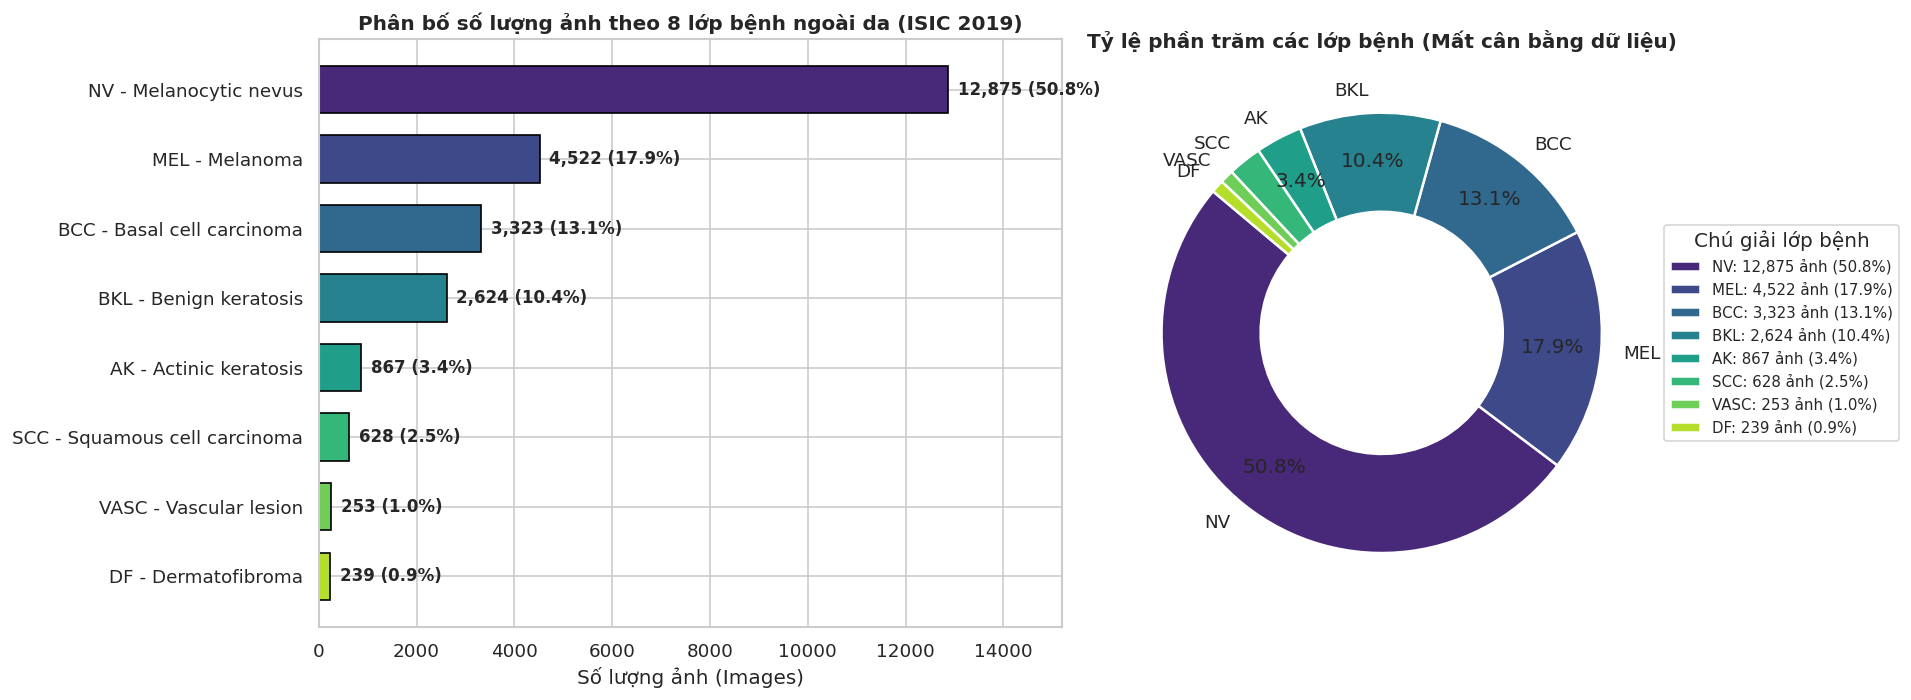

[SAVED FIGURE] -> /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/figures/02_sample_lesions_grid.png


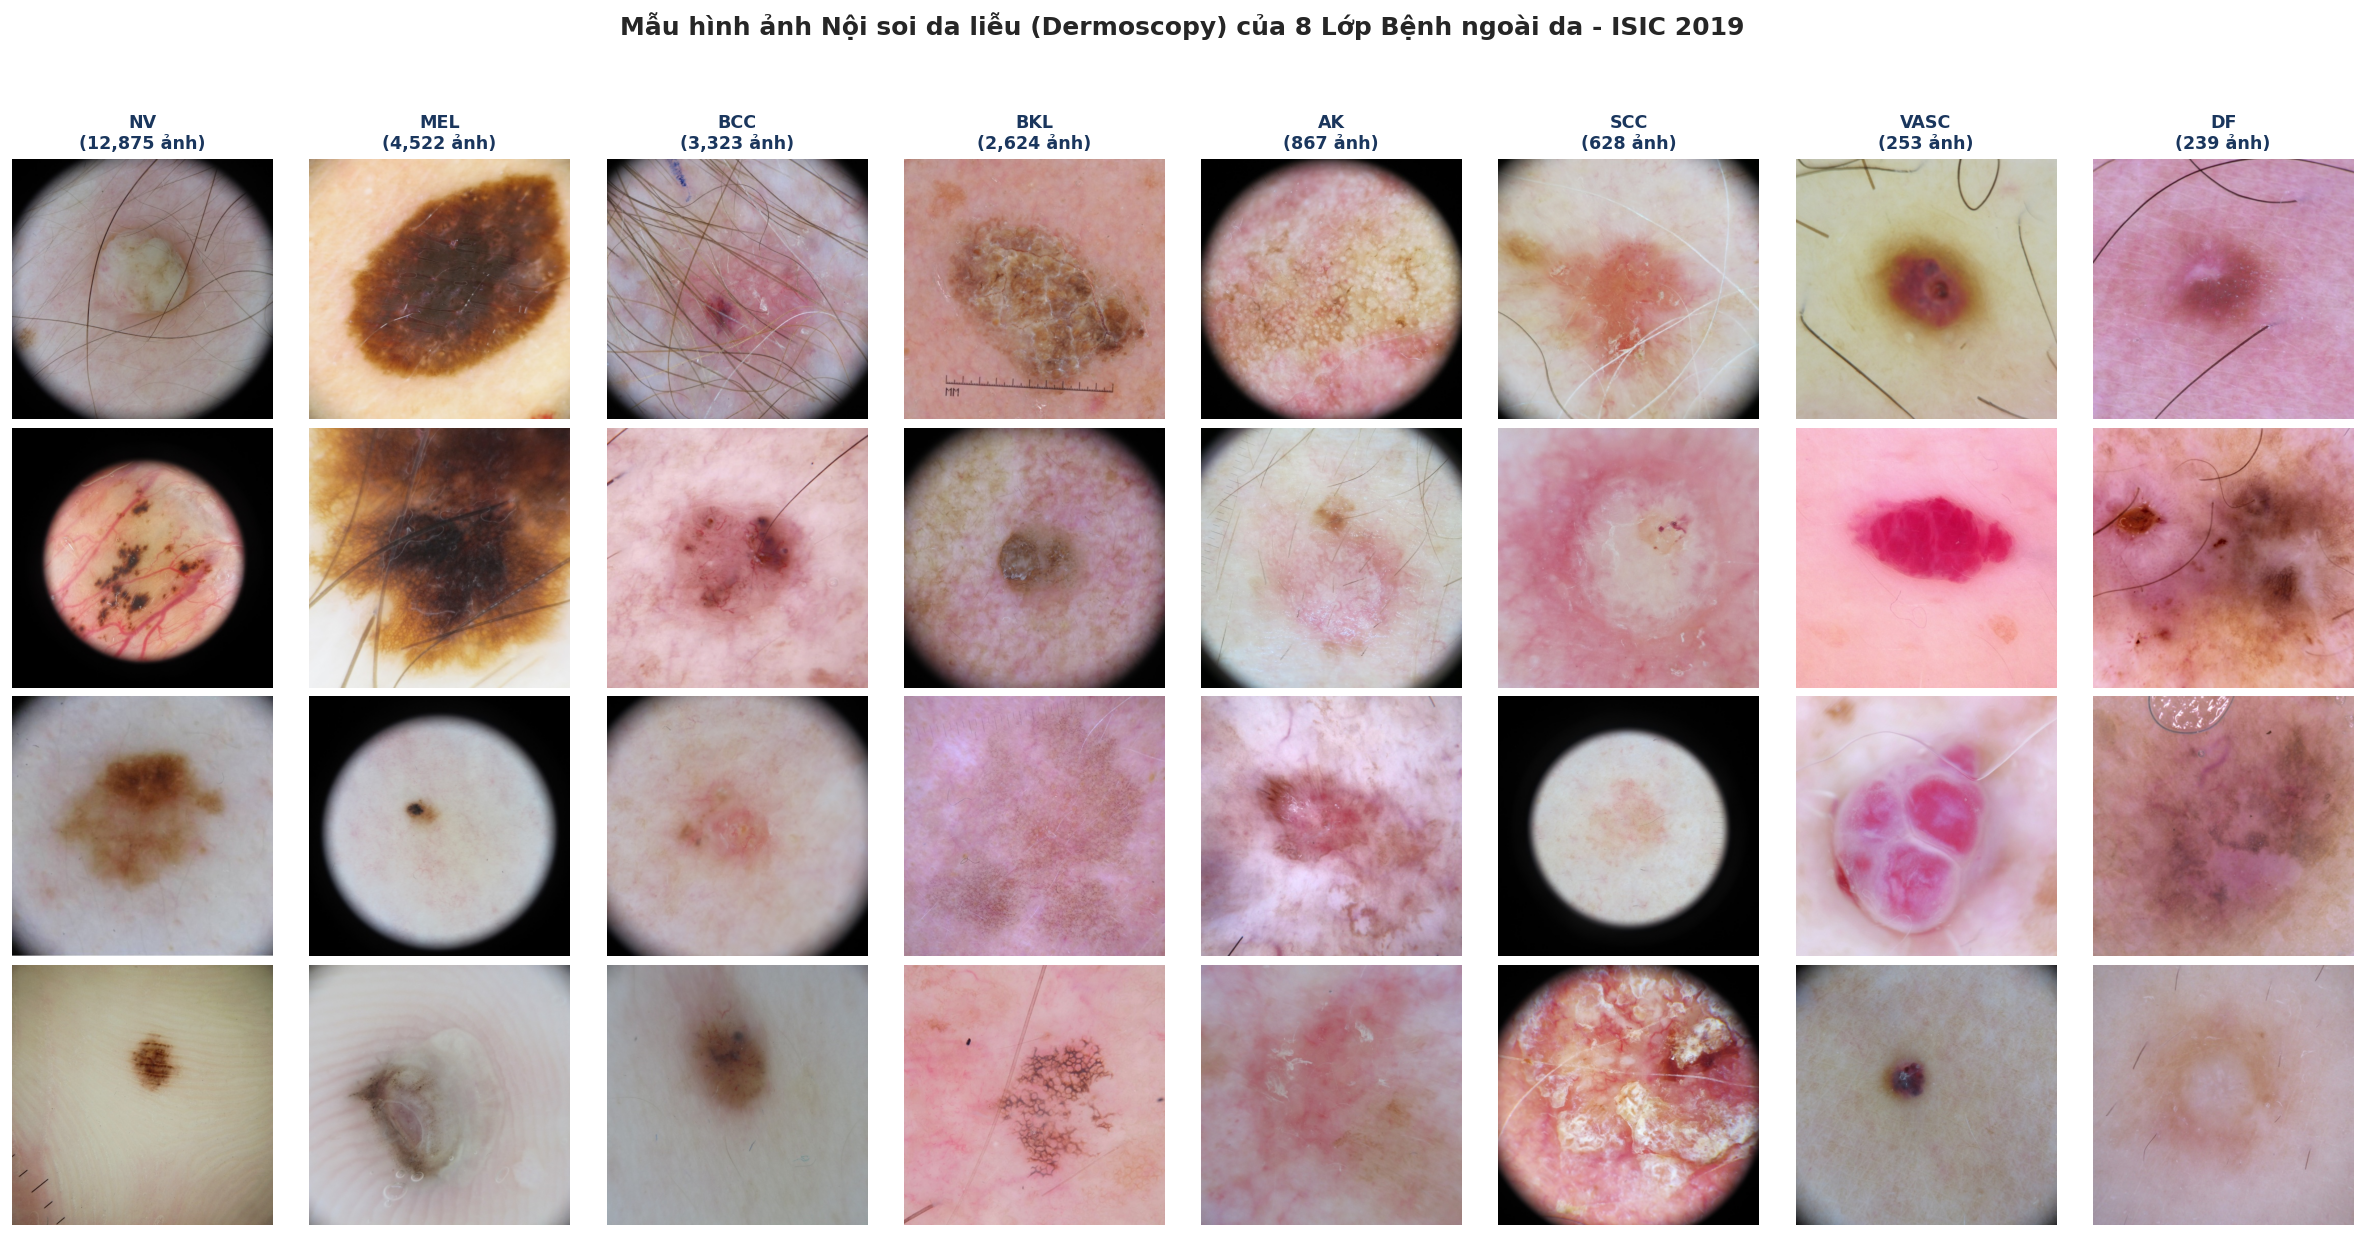

In [31]:
# ==============================================================================
# 4.1. THỐNG KÊ PHÂN BỐ 8 LỚP BỆNH & VẼ BIỂU ĐỒ 01_class_distribution.png
# ==============================================================================
class_counts = metadata_df["class_code"].value_counts().reindex(CLASS_CODES)
class_percents = (class_counts / len(metadata_df)) * 100.0

eda_summary_df = pd.DataFrame({
    "Label ID": range(len(CLASS_CODES)),
    "Mã bệnh (Code)": CLASS_CODES,
    "Tên bệnh lý": [CLASS_NAMES_VI[c] for c in CLASS_CODES],
    "Số lượng ảnh": class_counts.values,
    "Tỷ lệ (%)": class_percents.values.round(2)
})
display(eda_summary_df)
eda_summary_df.to_csv(os.path.join(REPORTS_DIR, "dataset_class_distribution.csv"), index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.35, 1.0]})
palette = sns.color_palette("viridis", len(CLASS_CODES))

# Biểu đồ cột ngang
bars = axes[0].barh(
    [f"{c} - {CLASS_NAMES_VI[c].split('(')[0].strip()}" for c in CLASS_CODES][::-1],
    class_counts.values[::-1],
    color=palette[::-1],
    edgecolor="black",
    height=0.68
)
axes[0].set_title("Phân bố số lượng ảnh theo 8 lớp bệnh ngoài da (ISIC 2019)", fontweight="bold")
axes[0].set_xlabel("Số lượng ảnh (Images)")
axes[0].set_xlim(0, max(class_counts.values) * 1.18)

for bar, cnt, pct in zip(bars, class_counts.values[::-1], class_percents.values[::-1]):
    axes[0].text(
        bar.get_width() + max(class_counts.values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{cnt:,} ({pct:.1f}%)",
        va="center", ha="left", fontsize=10, fontweight="bold"
    )

# Biểu đồ Donut tỷ lệ %
wedges, texts, autotexts = axes[1].pie(
    class_counts.values,
    labels=CLASS_CODES,
    autopct=lambda p: f"{p:.1f}%" if p > 3.0 else "",
    pctdistance=0.78,
    startangle=140,
    colors=palette,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=1.5)
)
axes[1].set_title("Tỷ lệ phần trăm các lớp bệnh (Mất cân bằng dữ liệu)", fontweight="bold")
axes[1].legend(
    wedges,
    [f"{c}: {cnt:,} ảnh ({pct:.1f}%)" for c, cnt, pct in zip(CLASS_CODES, class_counts.values, class_percents.values)],
    title="Chú giải lớp bệnh",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    fontsize=9
)

plt.tight_layout()
save_fig("01_class_distribution.png", fig)
plt.show()

# ==============================================================================
# 4.2. HIỂN THỊ LƯỚI ẢNH MẪU ĐẠI DIỆN CHO 8 BỆNH NGOÀI DA (02_sample_lesions_grid.png)
# ==============================================================================
fig, axes = plt.subplots(4, 8, figsize=(20, 10.5))
fig.suptitle("Mẫu hình ảnh Nội soi da liễu (Dermoscopy) của 8 Lớp Bệnh ngoài da - ISIC 2019", fontsize=15, fontweight="bold", y=0.98)

rng_vis = np.random.default_rng(42)
for col_idx, code in enumerate(CLASS_CODES):
    subset = metadata_df[metadata_df["class_code"] == code]
    sampled_rows = subset.sample(n=min(4, len(subset)), random_state=42)
    for row_idx, (_, row) in enumerate(sampled_rows.iterrows()):
        ax = axes[row_idx, col_idx]
        img_bgr = cv2.imread(row["image_path"])
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        ax.imshow(img_rgb)
        ax.axis("off")
        if row_idx == 0:
            ax.set_title(f"{code}\n({len(subset):,} ảnh)", fontsize=10.5, fontweight="bold", color="#1a365d")

plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig("02_sample_lesions_grid.png", fig)
plt.show()

## Phần 5: Phân Chia Tập Dữ Liệu Phân Tầng, Trọng Số Lớp Làm Mượt & Pipeline `tf.data.Dataset`

- Chia dữ liệu thành **70% Train – 15% Validation – 15% Test** (Stratified Split).
- Thiết lập **Dampened Class Weights** ($w_c = (\frac{N}{K \cdot N_c})^{0.5}$) để chống thiên lệch về lớp đa số `NV`.
- Xây dựng **Dermoscopy-Safe Augmentation** (lật ngang/dọc, xoay ngẫu nhiên, phóng đại nhẹ, chỉnh tương phản nhẹ).

Tập Huấn luyện (Train)      : 17,731 ảnh (70.0%)
Tập Kiểm định (Validation)  : 3,800 ảnh (15.0%)
Tập Kiểm tra (Test cố định) : 3,800 ảnh (15.0%)


,Mã lớp,Số mẫu Train,Trọng số tuyến tính (Beta=1.0),Trọng số làm mượt (Beta=0.5 - Sử dụng)
0,NV,9012,0.246,0.2691
1,MEL,3166,0.700,0.4540
2,BCC,2326,0.953,0.5296
3,BKL,1836,1.207,0.5961
4,AK,607,3.651,1.0368
5,SCC,440,5.037,1.2178
6,VASC,177,12.522,1.9200
7,DF,167,13.272,1.9766


[SAVED FIGURE] -> /content/drive/MyDrive/ChuyenDe_TGMT/Bài tập nhóm/figures/03_augmentation_preview.png


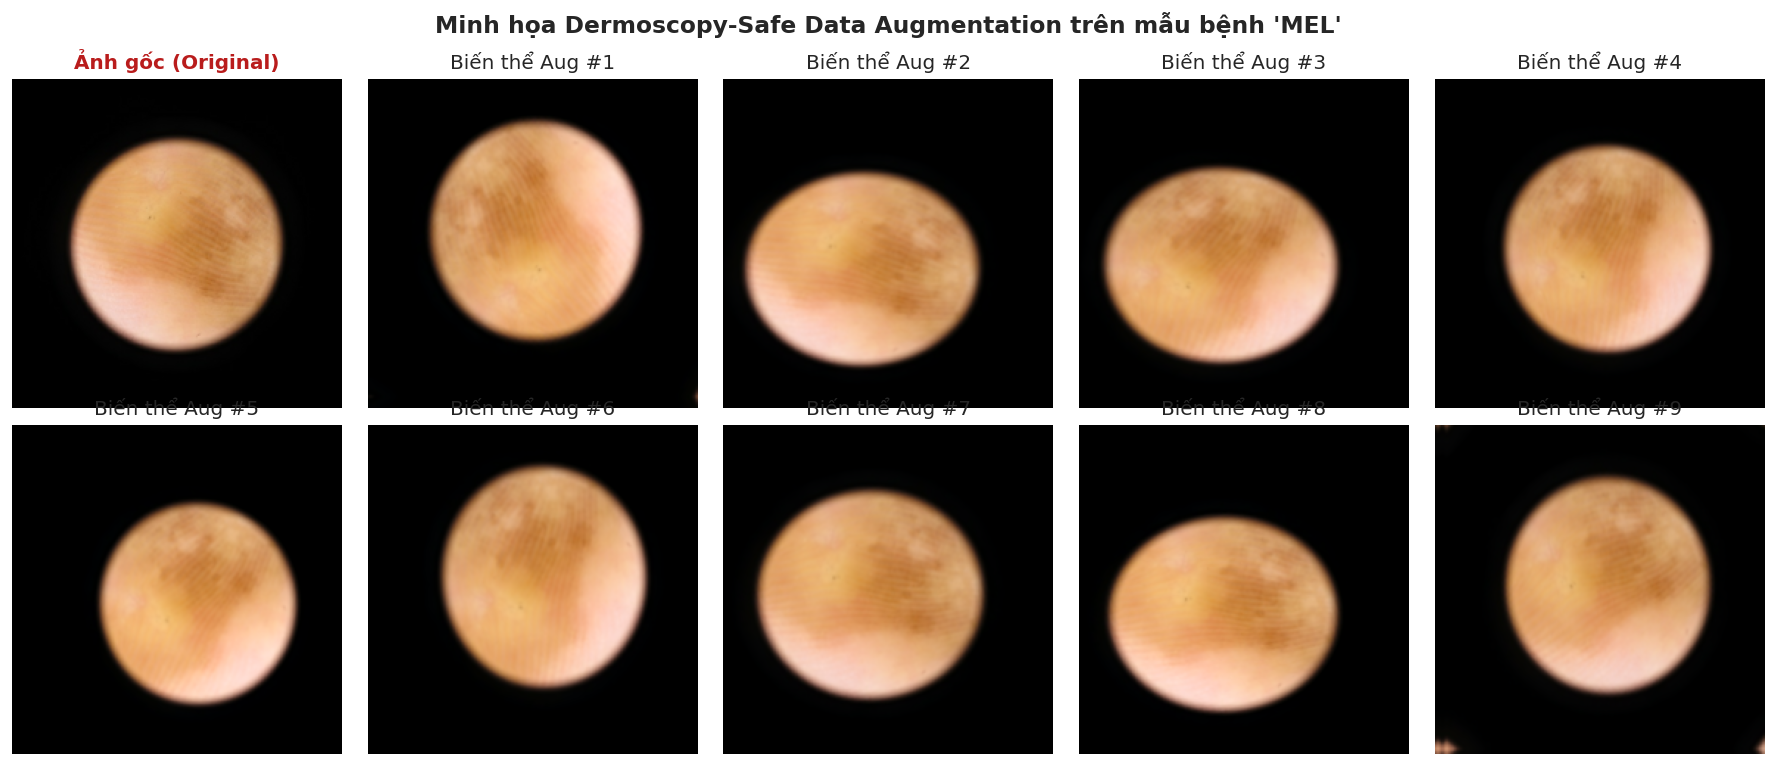

In [32]:
# ==============================================================================
# 5.1. CHIA DỮ LIỆU TRAIN (70%) / VALIDATION (15%) / TEST (15%) PHÂN TẦNG
# ==============================================================================
train_val_df, test_df = train_test_split(
    metadata_df,
    test_size=CONFIG["TEST_SIZE"],
    stratify=metadata_df["label"],
    random_state=CONFIG["SPLIT_SEED"]
)

relative_val_size = CONFIG["VAL_SIZE"] / (1.0 - CONFIG["TEST_SIZE"])
train_df, val_df = train_test_split(
    train_val_df,
    test_size=relative_val_size,
    stratify=train_val_df["label"],
    random_state=CONFIG["SPLIT_SEED"]
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print("==================================================================")
print(f"Tập Huấn luyện (Train)      : {len(train_df):,} ảnh ({len(train_df)/len(metadata_df)*100:.1f}%)")
print(f"Tập Kiểm định (Validation)  : {len(val_df):,} ảnh ({len(val_df)/len(metadata_df)*100:.1f}%)")
print(f"Tập Kiểm tra (Test cố định) : {len(test_df):,} ảnh ({len(test_df)/len(metadata_df)*100:.1f}%)")
print("==================================================================")

# ==============================================================================
# 5.2. TÍNH TOÁN TRỌNG SỐ LỚP LÀM MƯỢT (DAMPENED CLASS WEIGHTS)
# ==============================================================================
train_class_counts = train_df["label"].value_counts().sort_index().values
total_train = len(train_df)
num_classes = CONFIG["NUM_CLASSES"]

# Trọng số nghịch đảo tuyến tính (beta = 1.0) vs Trọng số làm mượt (beta = 0.5)
raw_inv_weights = total_train / (num_classes * train_class_counts)
dampened_weights = np.power(raw_inv_weights, CONFIG["CLASS_WEIGHT_BETA"])
# Chuẩn hóa để trung bình trọng số bằng 1.0
dampened_weights = dampened_weights / np.mean(dampened_weights)

CLASS_WEIGHT_DICT = {i: float(dampened_weights[i]) for i in range(num_classes)}

weight_df = pd.DataFrame({
    "Mã lớp": CLASS_CODES,
    "Số mẫu Train": train_class_counts,
    "Trọng số tuyến tính (Beta=1.0)": np.round(raw_inv_weights, 3),
    "Trọng số làm mượt (Beta=0.5 - Sử dụng)": np.round(dampened_weights, 4)
})
display(weight_df)

# ==============================================================================
# 5.3. XÂY DỰNG PIPELINE TF.DATA.DATASET TỐC ĐỘ CAO TỪ CACHE SSD
# ==============================================================================
AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = CONFIG["IMAGE_SIZE"]
BATCH_SIZE = CONFIG["BATCH_SIZE"]

def decode_and_resize_image(file_path, label):
    """
    Đọc ảnh JPEG từ SSD cache, giải mã RGB, resize bicubic về 224x224
    và trả về pixel trong miền [0, 255] kèm nhãn One-Hot float32.
    """
    img_bytes = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img_bytes, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE], method="bicubic", antialias=True)
    img = tf.clip_by_value(img, 0.0, 255.0)
    one_hot_label = tf.one_hot(label, depth=num_classes, dtype=tf.float32)
    return img, one_hot_label

def build_tf_dataset(df, training=False, seed=42, batch_size=None):
    paths = df["image_path"].values
    labels = df["label"].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(df), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(decode_and_resize_image, num_parallel_calls=AUTOTUNE)
    effective_batch_size = int(batch_size or CONFIG["BATCH_SIZE"])
    ds = ds.batch(effective_batch_size, drop_remainder=False)
    ds = ds.prefetch(AUTOTUNE)
    return ds

# Khởi tạo tập Validation và Test cố định
val_ds  = build_tf_dataset(val_df, training=False)
test_ds = build_tf_dataset(test_df, training=False)
y_test_true = test_df["label"].values.astype(np.int32)
y_val_true  = val_df["label"].values.astype(np.int32)

# ==============================================================================
# 5.4. TẦNG TĂNG CƯỜNG DỮ LIỆU CHUYÊN BIỆT CHO ẢNH DA LIỄU (DERMOSCOPY AUGMENTATION)
# ==============================================================================
def create_dermoscopy_augmentation(seed=42, name="dermoscopy_augmentation"):
    """
    Ảnh nội soi da không có hướng cố định trên-dưới nên bất biến với phép lật ngang/dọc
    và xoay. Giữ nguyên cấu trúc sắc tố màu, chỉ biến thiên nhẹ độ tương phản.
    """
    return keras.Sequential(
        [
            layers.RandomFlip("horizontal_and_vertical", seed=seed),
            layers.RandomRotation(factor=0.25, fill_mode="reflect", seed=seed),
            layers.RandomZoom(height_factor=(-0.10, 0.10), width_factor=(-0.10, 0.10), fill_mode="reflect", seed=seed),
            layers.RandomTranslation(height_factor=0.08, width_factor=0.08, fill_mode="reflect", seed=seed),
            layers.RandomContrast(factor=0.10, seed=seed),
        ],
        name=name
    )

# Trực quan hóa hiệu ứng Data Augmentation và lưu vào figures/03_augmentation_preview.png
aug_preview_layer = create_dermoscopy_augmentation(seed=42, name="aug_preview")
sample_batch_imgs, sample_batch_lbls = next(iter(val_ds))
sample_img = sample_batch_imgs[0:1]
sample_cls = CLASS_CODES[int(tf.argmax(sample_batch_lbls[0]).numpy())]

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
fig.suptitle(f"Minh họa Dermoscopy-Safe Data Augmentation trên mẫu bệnh '{sample_cls}'", fontsize=14, fontweight="bold")

for idx in range(10):
    ax = axes[idx // 5, idx % 5]
    if idx == 0:
        disp_img = np.asarray(sample_img[0], dtype=np.float32) / 255.0
        ax.set_title("Ảnh gốc (Original)", fontweight="bold", color="#b91c1c")
    else:
        aug_img = np.asarray(aug_preview_layer(sample_img, training=True)[0], dtype=np.float32)
        disp_img = np.clip(aug_img / 255.0, 0.0, 1.0)
        ax.set_title(f"Biến thể Aug #{idx}")
    disp_img = np.asarray(disp_img, dtype=np.float32)
    ax.imshow(disp_img)
    ax.axis("off")

plt.tight_layout()
save_fig("03_augmentation_preview.png", fig)
plt.show()

## Phần 6: Xây Dựng Các Mô-đun Kiến Trúc Tùy Chỉnh (Custom Layers & Attention Blocks)

Toàn bộ các lớp tùy chỉnh đều được đăng ký chuẩn `register_custom_layer` (hỗ trợ cả Keras 2, tf_keras và Keras 3) để tương thích tuyệt đối với chuẩn lưu trữ `.keras` của Keras 3:
1. **`ImageNetNormalization`**: Chuẩn hóa theo trung bình và độ lệch chuẩn ImageNet cho nhánh `DenseNet121` mà không cần dùng `Lambda` layer.
2. **`SqueezeExcitationBlock` (SE)**: Cơ chế chú ý kênh (*Channel Attention*) học trọng số ưu tiên cho từng bản đồ đặc trưng màu sắc/kết cấu.
3. **`CBAMBlock` (Convolutional Block Attention Module)**: Kết hợp tuần tự **Channel Attention** (trên cả Global AvgPool & Global MaxPool) và **Spatial Attention** (mặt nạ không gian $7\times7$ giúp tự động định vị vùng tổn thương da và triệt tiêu nhiễu lông/thước đo ở nền ảnh).
4. **`DualPoolingAttention`**: Học cổng chú ý $\alpha \in [0, 1]^C$ để kết hợp động giữa đặc trưng toàn cục trung bình (`GlobalAveragePooling2D`) và đặc trưng dị biệt cực đại cục bộ (`GlobalMaxPooling2D`).
5. **`GatedBottleneckAdapter`**: Cổng điều tiết phi tuyến hạng thấp $h' = h + \lambda(h) \odot \text{Swish}(h W_{\text{down}}) W_{\text{up}}$ theo phương pháp thiết kế Transfer Learning nâng cao.

In [33]:
# ==============================================================================
# 6.1. HÀM ĐĂNG KÝ SERIALIZATION TƯƠNG THÍCH MỌI PHIÊN BẢN (KERAS 2 / TF_KERAS / KERAS 3)
# ==============================================================================

def register_custom_layer(cls):
    """Đăng ký serialization an toàn đa nền tảng (Keras 2, tf_keras và Keras 3)."""
    for reg in [
        getattr(getattr(keras, "utils", None), "register_keras_serializable", None),
        getattr(getattr(keras, "saving", None), "register_keras_serializable", None),
        getattr(getattr(tf.keras, "utils", None), "register_keras_serializable", None)
    ]:
        if reg is not None:
            try:
                return reg(package="ISIC2019")(cls)
            except Exception:
                pass
    return cls


@register_custom_layer
class SqueezeExcitationBlock(layers.Layer):
    """Khối chú ý kênh Squeeze-and-Excitation (SE Block)."""
    def __init__(self, reduction_ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio

    def build(self, input_shape):
        channels = int(input_shape[-1])
        reduced_channels = max(4, channels // self.reduction_ratio)
        self.gap = layers.GlobalAveragePooling2D(keepdims=True)
        self.fc1 = layers.Conv2D(reduced_channels, kernel_size=1, activation="swish", kernel_initializer="he_normal")
        self.fc2 = layers.Conv2D(channels, kernel_size=1, activation="sigmoid", kernel_initializer="glorot_uniform")
        super().build(input_shape)

    def call(self, inputs):
        se = self.gap(inputs)
        se = self.fc1(se)
        se = self.fc2(se)
        return inputs * se

    def get_config(self):
        config = super().get_config()
        config.update({"reduction_ratio": self.reduction_ratio})
        return config


@register_custom_layer
class CBAMBlock(layers.Layer):
    """
    Convolutional Block Attention Module (CBAM):
    Kết hợp tuần tự Channel Attention (AvgPool + MaxPool MLP) và Spatial Attention (Conv 7x7).
    """
    def __init__(self, reduction_ratio=8, spatial_kernel=7, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = reduction_ratio
        self.spatial_kernel = spatial_kernel

    def build(self, input_shape):
        channels = int(input_shape[-1])
        reduced_channels = max(4, channels // self.reduction_ratio)

        # Channel Attention layers (shared MLP via 1x1 Conv)
        self.avg_pool = layers.GlobalAveragePooling2D(keepdims=True)
        self.max_pool = layers.GlobalMaxPooling2D(keepdims=True)
        self.shared_mlp_1 = layers.Conv2D(reduced_channels, kernel_size=1, activation="swish", kernel_initializer="he_normal")
        self.shared_mlp_2 = layers.Conv2D(channels, kernel_size=1, kernel_initializer="glorot_uniform")

        # Spatial Attention layer
        self.spatial_conv = layers.Conv2D(
            filters=1,
            kernel_size=self.spatial_kernel,
            padding="same",
            activation="sigmoid",
            kernel_initializer="glorot_uniform",
            use_bias=False
        )
        super().build(input_shape)

    def call(self, inputs):
        # 1. Channel Attention
        avg_out = self.shared_mlp_2(self.shared_mlp_1(self.avg_pool(inputs)))
        max_out = self.shared_mlp_2(self.shared_mlp_1(self.max_pool(inputs)))
        channel_gate = tf.sigmoid(avg_out + max_out)
        x = inputs * channel_gate

        # 2. Spatial Attention
        avg_spatial = tf.reduce_mean(x, axis=-1, keepdims=True)
        max_spatial = tf.reduce_max(x, axis=-1, keepdims=True)
        spatial_concat = tf.concat([avg_spatial, max_spatial], axis=-1)
        spatial_gate = self.spatial_conv(spatial_concat)
        return x * spatial_gate

    def get_config(self):
        config = super().get_config()
        config.update({
            "reduction_ratio": self.reduction_ratio,
            "spatial_kernel": self.spatial_kernel
        })
        return config


@register_custom_layer
class DualPoolingAttention(layers.Layer):
    """
    Cổng chú ý hai nhánh Pooling (Gated Global Average Pooling & Global Max Pooling):
    Tự động học cổng sigmoid cân bằng giữa đặc trưng nền trung bình (GAP) và điểm dị biệt cục bộ (GMP).
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.gap = layers.GlobalAveragePooling2D()
        self.gmp = layers.GlobalMaxPooling2D()

    def build(self, input_shape):
        channels = int(input_shape[-1])
        self.gate_dense = layers.Dense(channels, activation="sigmoid", kernel_initializer="glorot_uniform", name="dual_pool_gate")
        super().build(input_shape)

    def call(self, inputs):
        avg_feat = self.gap(inputs)
        max_feat = self.gmp(inputs)
        combined = tf.concat([avg_feat, max_feat], axis=-1)
        gate = self.gate_dense(combined)
        return gate * avg_feat + (tf.cast(1.0, gate.dtype) - gate) * max_feat

    def get_config(self):
        return super().get_config()


@register_custom_layer
class GatedBottleneckAdapter(layers.Layer):
    """
    Gated Bottleneck Adapter:
    h' = h + lambda(h) * W_up(Swish(W_down(h)))
    """
    def __init__(self, bottleneck_ratio=4, **kwargs):
        super().__init__(**kwargs)
        self.bottleneck_ratio = bottleneck_ratio

    def build(self, input_shape):
        channels = int(input_shape[-1])
        bottleneck_dim = max(8, channels // self.bottleneck_ratio)
        self.norm = layers.BatchNormalization()
        self.down_conv = layers.Conv2D(bottleneck_dim, kernel_size=1, activation="swish", kernel_initializer="he_normal")
        self.dw_conv = layers.DepthwiseConv2D(kernel_size=3, padding="same", activation="swish", depthwise_initializer="he_normal")
        self.up_conv = layers.Conv2D(channels, kernel_size=1, kernel_initializer="zeros")
        self.gap = layers.GlobalAveragePooling2D(keepdims=True)
        self.gate = layers.Conv2D(channels, kernel_size=1, activation="sigmoid", kernel_initializer="glorot_uniform")
        super().build(input_shape)

    def call(self, inputs):
        z = self.norm(inputs)
        adapter_out = self.up_conv(self.dw_conv(self.down_conv(z)))
        gate_val = self.gate(self.gap(inputs))
        return inputs + gate_val * adapter_out

    def get_config(self):
        config = super().get_config()
        config.update({"bottleneck_ratio": self.bottleneck_ratio})
        return config

print("[INFO] Đã khởi tạo thành công các Custom Serializable Layers đa phiên bản (Keras 2 / tf_keras / Keras 3).")

[INFO] Đã khởi tạo thành công các Custom Serializable Layers đa phiên bản (Keras 2 / tf_keras / Keras 3).


## Phần 7: Các kiến trúc CNN pretrained (giữ làm thư viện lựa chọn)

Notebook giữ định nghĩa cho `MobileNetV2`, `ResNet50V2`, `DenseNet121` và `EfficientNetB0` để các thành viên có thể chọn kiến trúc khác khi cần.

**Mặc định chỉ huấn luyện `DenseNet121`**. Ba mô hình pretrained còn lại không được khởi tạo/huấn luyện trong vòng lặp mặc định. DenseNet121 dùng trọng số ImageNet, đóng băng backbone ở giai đoạn đầu, sau đó rã đông một số tầng cuối và giữ Batch Normalization đóng băng khi fine-tuning.

In [34]:
# ==============================================================================
# 7.1. HÀM TẠO 4 MÔ HÌNH PRETRAINED CNN & CHIẾN LƯỢC ĐÓNG BĂNG / MỞ KHÓA
# ==============================================================================
def get_pretrained_backbone_and_preproc(model_name, input_shape):
    """Trả về (backbone, preprocessing_layer) tương thích hoàn toàn với Keras 3 saving."""
    if model_name == "MobileNetV2":
        backbone = keras.applications.MobileNetV2(
            include_top=False, weights="imagenet", input_shape=input_shape
        )
        preproc_layer = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="mobilenetv2_rescale")

    elif model_name == "ResNet50V2":
        backbone = keras.applications.ResNet50V2(
            include_top=False, weights="imagenet", input_shape=input_shape
        )
        preproc_layer = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="resnet50v2_rescale")

    elif model_name == "DenseNet121":
        backbone = keras.applications.DenseNet121(
            include_top=False, weights="imagenet", input_shape=input_shape
        )
        # Sử dụng layer Normalization chuẩn có sẵn của Keras (tương thích 100% mọi phiên bản)
        preproc_layer = layers.Normalization(
            mean=[0.485 * 255.0, 0.456 * 255.0, 0.406 * 255.0],
            variance=[(0.229 * 255.0)**2, (0.224 * 255.0)**2, (0.225 * 255.0)**2],
            name="densenet121_imagenet_norm"
        )

    elif model_name == "EfficientNetB0":
        backbone = keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_shape=input_shape
        )
        # EfficientNetB0 trong Keras đã tích hợp sẵn Rescaling & Normalization bên trong
        preproc_layer = layers.Identity(name="efficientnetb0_identity")

    else:
        raise ValueError(f"Mô hình Pretrained không hợp lệ: {model_name}")

    return backbone, preproc_layer


def build_pretrained_cnn(model_name, seed=42):
    """
    Xây dựng mô hình Transfer Learning chuẩn:
    Input -> Augmentation -> Preprocessing -> Pretrained Backbone -> GAP -> BN -> Dense(256, swish) -> Dropout -> Softmax(float32)
    """
    input_shape = (CONFIG["IMAGE_SIZE"], CONFIG["IMAGE_SIZE"], CONFIG["CHANNELS"])
    backbone, preproc_layer = get_pretrained_backbone_and_preproc(model_name, input_shape)

    # Giai đoạn 1: Đóng băng toàn bộ backbone
    backbone.trainable = False

    inputs = keras.Input(shape=input_shape, name="input_image")
    x = create_dermoscopy_augmentation(seed=seed, name=f"{model_name}_aug")(inputs)
    x = preproc_layer(x)

    # Truyền qua backbone
    x = backbone(x)

    # Classification Head
    x = layers.GlobalAveragePooling2D(name="head_gap")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(
        256,
        activation="swish",
        kernel_initializer="he_normal",
        kernel_regularizer=keras.regularizers.l2(1e-4),
        name="head_dense_256"
    )(x)
    x = layers.Dropout(CONFIG["DROPOUT_RATE"], seed=seed, name="head_dropout")(x)
    outputs = layers.Dense(
        CONFIG["NUM_CLASSES"],
        activation="softmax",
        dtype="float32",
        name="predictions"
    )(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name=model_name)
    return model, backbone


def unfreeze_top_layers_keep_bn_frozen(backbone, num_layers=35):
    """
    Mở khóa N tầng cuối của backbone để Fine-tune ở Stage 2,
    nhưng ĐÓNG BĂNG toàn bộ các lớp BatchNormalization để bảo vệ thống kê running mean/var.
    """
    backbone.trainable = True
    for layer in backbone.layers[:-num_layers]:
        layer.trainable = False

    for layer in backbone.layers[-num_layers:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = True

## Phần 8: Các kiến trúc CNN tự thiết kế (giữ làm thư viện lựa chọn)

Notebook có định nghĩa bốn kiến trúc custom để nhóm có thể lựa chọn: `Custom_MS_ResCNN`, `Custom_CBAM_ResNet`, `Custom_DS_SE_DualPoolNet` và `Custom_Gated_DenseResNet`.

**Mặc định chỉ chạy `Custom_Gated_DenseResNet`**. Mô hình được huấn luyện từ đầu; ba cấu hình tham số sẽ so sánh batch size, learning rate và dropout. Các kiến trúc custom còn lại không nằm trong danh sách chạy mặc định.

In [35]:
# ==============================================================================
# 8.1. CÁC KHỐI XÂY DỰNG CƠ SỞ CHO 4 MÔ HÌNH CUSTOM CNN
# ==============================================================================

def conv_bn_swish(x, filters, kernel_size=3, strides=1, dilation_rate=1, name=None):
    x = layers.Conv2D(
        filters,
        kernel_size=kernel_size,
        strides=strides,
        dilation_rate=dilation_rate,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        name=f"{name}_conv" if name else None
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn" if name else None)(x)
    x = layers.Activation("swish", name=f"{name}_swish" if name else None)(x)
    return x


# ------------------------------------------------------------------------------
# CUSTOM MODEL 1: Custom_MS_ResCNN (Multi-Scale Inception + Residual Network)
# ------------------------------------------------------------------------------
def multiscale_residual_block(inputs, filters, stride=1, name="ms_res"):
    shortcut = inputs
    if stride > 1:
        x_in = layers.MaxPooling2D(pool_size=2, strides=2, padding="same", name=f"{name}_pool")(inputs)
    else:
        x_in = inputs

    branch_ch = filters // 4
    # Nhánh 1: 1x1 Conv (Đặc trưng màu sắc điểm ảnh cục bộ)
    b1 = conv_bn_swish(x_in, branch_ch, kernel_size=1, name=f"{name}_b1_1x1")

    # Nhánh 2: 3x3 Conv (Kết cấu mạng lưới sắc tố tầm trung)
    b2 = conv_bn_swish(x_in, branch_ch, kernel_size=1, name=f"{name}_b2_reduce")
    b2 = conv_bn_swish(b2, branch_ch * 2, kernel_size=3, name=f"{name}_b2_3x3")

    # Nhánh 3: Dilated 3x3 Conv, rate=2 (Trường nhìn rộng 5x5 bắt biên tổn thương lớn)
    b3 = conv_bn_swish(x_in, branch_ch, kernel_size=1, name=f"{name}_b3_reduce")
    b3 = conv_bn_swish(b3, branch_ch, kernel_size=3, dilation_rate=2, name=f"{name}_b3_dilated")

    merged = layers.Concatenate(axis=-1, name=f"{name}_concat")([b1, b2, b3])
    merged = layers.Conv2D(
        filters, kernel_size=1, padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_proj_conv"
    )(merged)
    merged = layers.BatchNormalization(name=f"{name}_proj_bn")(merged)

    if stride != 1 or int(inputs.shape[-1]) != filters:
        shortcut = layers.Conv2D(
            filters, kernel_size=1, strides=stride, padding="same",
            use_bias=False, kernel_initializer="he_normal", name=f"{name}_short_conv"
        )(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_short_bn")(shortcut)

    out = layers.Add(name=f"{name}_add")([merged, shortcut])
    out = layers.Activation("swish", name=f"{name}_out")(out)
    return out


def build_custom_ms_rescnn(seed=42):
    input_shape = (CONFIG["IMAGE_SIZE"], CONFIG["IMAGE_SIZE"], CONFIG["CHANNELS"])
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = create_dermoscopy_augmentation(seed=seed, name="ms_rescnn_aug")(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)

    # Stem
    x = conv_bn_swish(x, 32, kernel_size=3, strides=2, name="stem_1")
    x = conv_bn_swish(x, 32, kernel_size=3, strides=1, name="stem_2")

    # 4 Multi-Scale Residual Stages
    x = multiscale_residual_block(x, filters=64,  stride=2, name="stage1_b1")
    x = multiscale_residual_block(x, filters=64,  stride=1, name="stage1_b2")
    x = multiscale_residual_block(x, filters=128, stride=2, name="stage2_b1")
    x = multiscale_residual_block(x, filters=128, stride=1, name="stage2_b2")
    x = multiscale_residual_block(x, filters=256, stride=2, name="stage3_b1")
    x = multiscale_residual_block(x, filters=256, stride=1, name="stage3_b2")
    x = multiscale_residual_block(x, filters=384, stride=2, name="stage4_b1")

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation="swish", kernel_initializer="he_normal",
                     kernel_regularizer=keras.regularizers.l2(1e-4), name="head_fc")(x)
    x = layers.Dropout(CONFIG["DROPOUT_RATE"], seed=seed, name="head_drop")(x)
    outputs = layers.Dense(CONFIG["NUM_CLASSES"], activation="softmax", dtype="float32", name="predictions")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="Custom_MS_ResCNN")


# ------------------------------------------------------------------------------
# CUSTOM MODEL 2: Custom_CBAM_ResNet (Residual CNN + CBAM Channel & Spatial Attention)
# ------------------------------------------------------------------------------
def cbam_residual_block(inputs, filters, stride=1, name="cbam_res"):
    shortcut = inputs
    x = conv_bn_swish(inputs, filters, kernel_size=3, strides=stride, name=f"{name}_c1")
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False,
                      kernel_initializer="he_normal", name=f"{name}_c2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)

    # Tích hợp mô-đun chú ý kép CBAM (Channel + Spatial Attention)
    x = CBAMBlock(reduction_ratio=8, spatial_kernel=7, name=f"{name}_cbam")(x)

    if stride != 1 or int(inputs.shape[-1]) != filters:
        shortcut = layers.Conv2D(filters, kernel_size=1, strides=stride, padding="same",
                                 use_bias=False, kernel_initializer="he_normal", name=f"{name}_short_conv")(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_short_bn")(shortcut)

    out = layers.Add(name=f"{name}_add")([x, shortcut])
    out = layers.Activation("swish", name=f"{name}_out")(out)
    return out


def build_custom_cbam_resnet(seed=42):
    input_shape = (CONFIG["IMAGE_SIZE"], CONFIG["IMAGE_SIZE"], CONFIG["CHANNELS"])
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = create_dermoscopy_augmentation(seed=seed, name="cbam_resnet_aug")(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)

    x = conv_bn_swish(x, 32, kernel_size=3, strides=2, name="stem")
    x = cbam_residual_block(x, filters=64,  stride=2, name="stage1_1")
    x = cbam_residual_block(x, filters=64,  stride=1, name="stage1_2")
    x = cbam_residual_block(x, filters=128, stride=2, name="stage2_1")
    x = cbam_residual_block(x, filters=128, stride=1, name="stage2_2")
    x = cbam_residual_block(x, filters=256, stride=2, name="stage3_1")
    x = cbam_residual_block(x, filters=256, stride=1, name="stage3_2")
    x = cbam_residual_block(x, filters=384, stride=2, name="stage4_1")

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation="swish", kernel_initializer="he_normal",
                     kernel_regularizer=keras.regularizers.l2(1e-4), name="head_fc")(x)
    x = layers.Dropout(CONFIG["DROPOUT_RATE"], seed=seed, name="head_drop")(x)
    outputs = layers.Dense(CONFIG["NUM_CLASSES"], activation="softmax", dtype="float32", name="predictions")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="Custom_CBAM_ResNet")


# ------------------------------------------------------------------------------
# CUSTOM MODEL 3: Custom_DS_SE_DualPoolNet (Depthwise Separable + SE + DualPooling)
# ------------------------------------------------------------------------------
def ds_se_block(inputs, filters, stride=1, name="ds_se"):
    shortcut = inputs
    x = layers.DepthwiseConv2D(
        kernel_size=3, strides=stride, padding="same", use_bias=False,
        depthwise_initializer="he_normal", name=f"{name}_dw"
    )(inputs)
    x = layers.BatchNormalization(name=f"{name}_dw_bn")(x)
    x = layers.Activation("swish", name=f"{name}_dw_swish")(x)

    x = layers.Conv2D(
        filters, kernel_size=1, padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_pw"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_pw_bn")(x)
    x = SqueezeExcitationBlock(reduction_ratio=8, name=f"{name}_se")(x)

    if stride == 1 and int(inputs.shape[-1]) == filters:
        x = layers.Add(name=f"{name}_add")([x, shortcut])
    x = layers.Activation("swish", name=f"{name}_out")(x)
    return x


def build_custom_ds_se_dualpoolnet(seed=42):
    input_shape = (CONFIG["IMAGE_SIZE"], CONFIG["IMAGE_SIZE"], CONFIG["CHANNELS"])
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = create_dermoscopy_augmentation(seed=seed, name="ds_se_aug")(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)

    x = conv_bn_swish(x, 32, kernel_size=3, strides=2, name="stem")
    x = ds_se_block(x, filters=64,  stride=2, name="stage1_1")
    x = ds_se_block(x, filters=64,  stride=1, name="stage1_2")
    x = ds_se_block(x, filters=128, stride=2, name="stage2_1")
    x = ds_se_block(x, filters=128, stride=1, name="stage2_2")
    x = ds_se_block(x, filters=128, stride=1, name="stage2_3")
    x = ds_se_block(x, filters=256, stride=2, name="stage3_1")
    x = ds_se_block(x, filters=256, stride=1, name="stage3_2")
    x = ds_se_block(x, filters=256, stride=1, name="stage3_3")
    x = ds_se_block(x, filters=384, stride=2, name="stage4_1")
    x = ds_se_block(x, filters=384, stride=1, name="stage4_2")

    # Cổng chú ý hai nhánh Pooling (Gated GAP + GMP)
    x = DualPoolingAttention(name="dual_pooling_attention")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation="swish", kernel_initializer="he_normal",
                     kernel_regularizer=keras.regularizers.l2(1e-4), name="head_fc")(x)
    x = layers.Dropout(CONFIG["DROPOUT_RATE"], seed=seed, name="head_drop")(x)
    outputs = layers.Dense(CONFIG["NUM_CLASSES"], activation="softmax", dtype="float32", name="predictions")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="Custom_DS_SE_DualPoolNet")


# ------------------------------------------------------------------------------
# CUSTOM MODEL 4: Custom_Gated_DenseResNet (Dense Low-level + Residual & Gated Adapter)
# ------------------------------------------------------------------------------
def dense_micro_layer(inputs, growth_rate=32, name="dense_l"):
    x = conv_bn_swish(inputs, growth_rate * 2, kernel_size=1, name=f"{name}_bottleneck")
    x = conv_bn_swish(x, growth_rate, kernel_size=3, name=f"{name}_conv3x3")
    return layers.Concatenate(axis=-1, name=f"{name}_concat")([inputs, x])


def transition_down(inputs, out_channels, name="trans"):
    x = conv_bn_swish(inputs, out_channels, kernel_size=1, name=f"{name}_1x1")
    x = layers.AveragePooling2D(pool_size=2, strides=2, padding="same", name=f"{name}_pool")(x)
    return x


def build_custom_gated_denseresnet(seed=42):
    input_shape = (CONFIG["IMAGE_SIZE"], CONFIG["IMAGE_SIZE"], CONFIG["CHANNELS"])
    inputs = keras.Input(shape=input_shape, name="input_image")
    x = create_dermoscopy_augmentation(seed=seed, name="gated_denseres_aug")(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)

    # Stem
    x = conv_bn_swish(x, 32, kernel_size=3, strides=2, name="stem")

    # Stage 1 & 2: Dense Connectivity bảo toàn đặc trưng màu sắc/vân da mức thấp
    for i in range(3):
        x = dense_micro_layer(x, growth_rate=24, name=f"dense_s1_{i}")
    x = transition_down(x, out_channels=96, name="trans_s1")

    for i in range(3):
        x = dense_micro_layer(x, growth_rate=32, name=f"dense_s2_{i}")
    x = transition_down(x, out_channels=160, name="trans_s2")

    # Stage 3 & 4: Residual + Gated Bottleneck Adapter ở các tầng ngữ nghĩa cao
    x = conv_bn_swish(x, 256, kernel_size=3, strides=2, name="res_s3_down")
    x = GatedBottleneckAdapter(bottleneck_ratio=4, name="gated_adapter_s3_1")(x)
    x = GatedBottleneckAdapter(bottleneck_ratio=4, name="gated_adapter_s3_2")(x)

    x = conv_bn_swish(x, 384, kernel_size=3, strides=2, name="res_s4_down")
    x = GatedBottleneckAdapter(bottleneck_ratio=4, name="gated_adapter_s4_1")(x)
    x = GatedBottleneckAdapter(bottleneck_ratio=4, name="gated_adapter_s4_2")(x)

    x = DualPoolingAttention(name="dual_pooling_head")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation="swish", kernel_initializer="he_normal",
                     kernel_regularizer=keras.regularizers.l2(1e-4), name="head_fc")(x)
    x = layers.Dropout(CONFIG["DROPOUT_RATE"], seed=seed, name="head_drop")(x)
    outputs = layers.Dense(CONFIG["NUM_CLASSES"], activation="softmax", dtype="float32", name="predictions")(x)
    return keras.Model(inputs=inputs, outputs=outputs, name="Custom_Gated_DenseResNet")


def build_custom_cnn(model_name, seed=42):
    if model_name == "Custom_MS_ResCNN":
        return build_custom_ms_rescnn(seed=seed)
    elif model_name == "Custom_CBAM_ResNet":
        return build_custom_cbam_resnet(seed=seed)
    elif model_name == "Custom_DS_SE_DualPoolNet":
        return build_custom_ds_se_dualpoolnet(seed=seed)
    elif model_name == "Custom_Gated_DenseResNet":
        return build_custom_gated_denseresnet(seed=seed)
    else:
        raise ValueError(f"Mô hình Custom không hợp lệ: {model_name}")

# Kiểm tra kích thước tham số CHỈ cho các mô hình đang chạy mặc định.
# Các kiến trúc khác vẫn được định nghĩa phía trên nhưng không khởi tạo ở cell này.
arch_overview = []
_original_dropout = CONFIG["DROPOUT_RATE"]
CONFIG["DROPOUT_RATE"] = 0.35
for m_name in ACTIVE_MODEL_NAMES:
    tf.keras.backend.clear_session()
    if m_name in PRETRAINED_MODEL_NAMES:
        m, bb = build_pretrained_cnn(m_name, seed=42)
        total_p = m.count_params()
        stage1_train_p = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
        hp_example = PARAMETER_CONFIGS[m_name][1]
        unfreeze_top_layers_keep_bn_frozen(bb, hp_example["UNFREEZE_LAST_LAYERS"])
        stage2_train_p = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
        arch_overview.append({
            "Mô hình": m_name,
            "Nhóm": "Pretrained (Transfer Learning + Fine-tuning)",
            "Tổng tham số": total_p,
            "Tham số Train (Stage 1)": stage1_train_p,
            "Tham số Train (Final/Stage 2)": stage2_train_p,
            "Tỷ lệ tham số học ρ (%)": round(stage2_train_p / max(1, total_p) * 100, 2),
        })
    else:
        m = build_custom_cnn(m_name, seed=42)
        total_p = m.count_params()
        train_p = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
        arch_overview.append({
            "Mô hình": m_name,
            "Nhóm": "Custom CNN (Tự thiết kế, train from scratch)",
            "Tổng tham số": total_p,
            "Tham số Train (Stage 1)": train_p,
            "Tham số Train (Final/Stage 2)": train_p,
            "Tỷ lệ tham số học ρ (%)": round(train_p / max(1, total_p) * 100, 2),
        })
    del m
    gc.collect()
CONFIG["DROPOUT_RATE"] = _original_dropout

arch_df = pd.DataFrame(arch_overview)
display(arch_df)
arch_df.to_csv(os.path.join(REPORTS_DIR, "model_architecture_parameters.csv"), index=False, encoding="utf-8-sig")


,Mô hình,Nhóm,Tổng tham số,Tham số Train (Stage 1),Tham số Train (Final/Stage 2),Tỷ lệ tham số học ρ (%)
0,DenseNet121,Pretrained (Transfer Learning + Fine-tuning),7306056,266504,430344,5.89
1,Custom_Gated_DenseResNet,"Custom CNN (Tự thiết kế, train from scratch)",2467336,2461144,2461144,99.75


## Phần 9: Huấn luyện và đánh giá — tùy chọn mô hình, cấu hình và seed

- Mặc định chạy `DenseNet121` và `Custom_Gated_DenseResNet`.
- Mỗi mô hình có 3 cấu hình siêu tham số (A/B/C; D1/D2/D3 cho DenseNet, C1/C2/C3 cho custom).
- Mặc định chỉ chạy seed `42` để tiết kiệm tài nguyên. Chọn cấu hình ở `ACTIVE_CONFIG_IDS`; chạy đủ sáu cấu hình mặc định là **6 lượt**, còn 3 seed sẽ là **18 lượt**.
- Có Auto-Resume theo khóa `(Model, Config_ID, Run_Index)`. Checkpoint của phiên thực nghiệm này dùng tên file mới để tránh nạp nhầm checkpoint cũ của thí nghiệm 8 mô hình.
- `val_loss` được dùng cho EarlyStopping/ModelCheckpoint; Macro-F1 trên Validation được dùng để chọn checkpoint/configuration. Các chỉ số trên Test được lưu để báo cáo, không dùng trực tiếp làm tiêu chí chọn mô hình.

In [ ]:
# ============================================================================
# 9.1. HÀM SEED, COMPILE, CALLBACKS VÀ ĐÁNH GIÁ
# ============================================================================
def set_global_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


def compile_cnn_model(model, learning_rate):
    optimizer = keras.optimizers.AdamW(
        learning_rate=float(learning_rate),
        weight_decay=CONFIG["WEIGHT_DECAY"]
    )
    loss_fn = keras.losses.CategoricalCrossentropy(
        label_smoothing=CONFIG["LABEL_SMOOTHING"]
    )
    model.compile(
        optimizer=optimizer,
        loss=loss_fn,
        metrics=[keras.metrics.CategoricalAccuracy(name="accuracy")]
    )


def build_training_callbacks(temp_ckpt_path):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=temp_ckpt_path, monitor="val_loss", mode="min",
            save_best_only=True, verbose=0
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min",
            patience=CONFIG["EARLY_STOPPING_PATIENCE"],
            restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", mode="min", factor=CONFIG["LR_FACTOR"],
            patience=CONFIG["LR_PATIENCE"], min_lr=CONFIG["MIN_LR"], verbose=1
        ),
        keras.callbacks.TerminateOnNaN()
    ]


def merge_stage_histories(h1, h2):
    merged = {}
    all_keys = set(h1.history) | set(h2.history)
    for key in all_keys:
        merged[key] = list(h1.history.get(key, [])) + list(h2.history.get(key, []))
    return merged


def evaluate_predictions_comprehensive(
    y_true, y_prob, model_name, model_group, config_id, config_name,
    run_idx, seed, train_time_s, infer_ms_per_img, total_params,
    trainable_params, val_macro_f1, hp
):
    y_pred = np.argmax(y_prob, axis=1)
    y_true_bin = label_binarize(y_true, classes=list(range(CONFIG["NUM_CLASSES"])))

    acc = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    macro_prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    macro_rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    weighted_prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    weighted_rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    try:
        macro_auc = roc_auc_score(y_true_bin, y_prob, average="macro", multi_class="ovr")
    except Exception:
        macro_auc = np.nan

    per_class_f1 = f1_score(
        y_true, y_pred, average=None,
        labels=list(range(CONFIG["NUM_CLASSES"])), zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=list(range(CONFIG["NUM_CLASSES"])))

    record = {
        "Model": model_name,
        "Group": model_group,
        "Config_ID": config_id,
        "Config_Name": config_name,
        "Config_Label": f"{model_name} | {config_id}",
        "Run": f"Run {run_idx}",
        "Run_Index": int(run_idx),
        "Seed": int(seed),
        "Val_Macro_F1": float(val_macro_f1),
        "Batch_Size": int(hp["BATCH_SIZE"]),
        "Head_LR": hp["HEAD_LR"],
        "Fine_Tune_LR": hp["FINE_TUNE_LR"],
        "Unfreeze_Last_Layers": hp["UNFREEZE_LAST_LAYERS"],
        "Dropout_Rate": float(hp["DROPOUT_RATE"]),
        "Custom_LR": hp["CUSTOM_LR"],
        "Accuracy": float(acc),
        "Balanced_Accuracy": float(bal_acc),
        "Macro_Precision": float(macro_prec),
        "Macro_Recall": float(macro_rec),
        "Macro_F1": float(macro_f1),
        "Weighted_Precision": float(weighted_prec),
        "Weighted_Recall": float(weighted_rec),
        "Weighted_F1": float(weighted_f1),
        "Macro_ROC_AUC": float(macro_auc),
        "Training_Time_s": float(train_time_s),
        "Inference_ms_per_img": float(infer_ms_per_img),
        "Total_Params": int(total_params),
        "Trainable_Params": int(trainable_params),
        "Trainable_Ratio_Pct": float(round(trainable_params / max(1, total_params) * 100, 2)),
    }
    for cls_idx, cls_code in enumerate(CLASS_CODES):
        record[f"F1_{cls_code}"] = float(per_class_f1[cls_idx])
    return record, cm


# ============================================================================
# 9.2. VÒNG LẶP THỰC NGHIỆM: chạy những cấu hình được chọn trong ACTIVE_CONFIG_IDS
# ============================================================================
# Tổng dự kiến tính theo toàn bộ cấu hình của mô hình đang bật; giúp theo dõi tiến độ
# khi chạy từng ID lần lượt. ACTIVE_CONFIG_IDS KHÔNG đưa vào RUN_SIGNATURE để các đợt
# D1 -> D2 -> ... có thể tiếp tục tích lũy vào cùng checkpoint.
TOTAL_EXPECTED_RUNS = sum(len(PARAMETER_CONFIGS[m]) for m in ACTIVE_MODEL_NAMES) * len(CONFIG["RUN_SEEDS"])
CHECKPOINT_STATE_PATH = os.path.join(REPORTS_DIR, "checkpoint_hparam_sweep_v1.pkl")
LOCAL_TMP_DIR = "/content/tmp_checkpoints_hparam_sweep" if IN_COLAB else os.path.join(WORKSPACE_DIR, "tmp_checkpoints_hparam_sweep")
os.makedirs(LOCAL_TMP_DIR, exist_ok=True)

RUN_SIGNATURE = json.dumps({
    "active_models": ACTIVE_MODEL_NAMES,
    "parameter_configs": PARAMETER_CONFIGS,
    "run_seeds": CONFIG["RUN_SEEDS"],
    "image_size": CONFIG["IMAGE_SIZE"],
    "num_classes": CONFIG["NUM_CLASSES"],
    "split_seed": CONFIG["SPLIT_SEED"],
    "val_size": CONFIG["VAL_SIZE"],
    "test_size": CONFIG["TEST_SIZE"],
    "head_epochs": CONFIG["HEAD_EPOCHS"],
    "fine_tune_epochs": CONFIG["FINE_TUNE_EPOCHS"],
    "custom_epochs": CONFIG["CUSTOM_EPOCHS"],
    "early_stopping_patience": CONFIG["EARLY_STOPPING_PATIENCE"],
}, sort_keys=True, ensure_ascii=False)

if os.path.exists(CHECKPOINT_STATE_PATH):
    try:
        with open(CHECKPOINT_STATE_PATH, "rb") as f:
            loaded_state = pickle.load(f)
        if loaded_state.get("schema_version") == 2 and loaded_state.get("run_signature") == RUN_SIGNATURE:
            experiment_state = loaded_state
            print(f"[AUTO-RESUME] Đã tải {len(experiment_state['records'])}/{TOTAL_EXPECTED_RUNS} lượt từ checkpoint hiện tại.")
        else:
            print("[AUTO-RESUME] Checkpoint không cùng cấu hình/schema; khởi tạo trạng thái mới để tránh trộn kết quả.")
            raise ValueError("Checkpoint signature mismatch")
    except Exception as exc:
        print(f"[INFO] Không dùng checkpoint cũ ({exc}); tạo trạng thái thực nghiệm mới.")
        experiment_state = None
else:
    experiment_state = None

if experiment_state is None:
    experiment_state = {
        "schema_version": 2,
        "run_signature": RUN_SIGNATURE,
        "records": [],
        "histories": {},             # key: (model, config_id, run_idx)
        "confusion_matrices": {},    # key: (model, config_id, run_idx)
        "test_probs": {},            # key: (model, config_id, run_idx)
        "best_val_macro_f1": {},     # key: model__config_id
    }

for model_name in ACTIVE_MODEL_NAMES:
    is_pretrained = model_name in PRETRAINED_MODEL_NAMES
    model_group = "Pretrained CNN" if is_pretrained else "Custom CNN"

    if model_name not in PARAMETER_CONFIGS:
        raise KeyError(f"Chưa khai báo 3 bộ tham số trong PARAMETER_CONFIGS cho {model_name}.")
    if len(PARAMETER_CONFIGS[model_name]) != 3:
        raise ValueError(f"Mô hình {model_name} phải có đúng 3 cấu hình tham số; hiện có {len(PARAMETER_CONFIGS[model_name])}.")

    selected_ids = ACTIVE_CONFIG_IDS.get(model_name, [])
    selected_hps = [hp for hp in PARAMETER_CONFIGS[model_name] if hp["Config_ID"] in selected_ids]
    if not selected_hps:
        print(f"[SKIP CONFIGS] Không chọn cấu hình nào cho {model_name} trong ACTIVE_CONFIG_IDS.")
    for hp in selected_hps:
        config_id = hp["Config_ID"]
        config_name = hp["Config_Name"]
        config_key = f"{model_name}__{config_id}"

        for run_idx, seed in enumerate(CONFIG["RUN_SEEDS"], start=1):
            run_key = (model_name, config_id, run_idx)
            already_done = any(
                r["Model"] == model_name and r["Config_ID"] == config_id and r["Run_Index"] == run_idx
                for r in experiment_state["records"]
            )
            if already_done:
                print(f"[SKIP] {model_name} | {config_id} | Run {run_idx} (seed={seed}) đã hoàn thành.")
                continue

            print("\\n" + "=" * 92)
            print(f"MODEL={model_name} | CONFIG={config_id}: {config_name} | RUN {run_idx}/{CONFIG['NUM_RUNS']} | SEED={seed}")
            print(f"Hyperparameters: batch={hp['BATCH_SIZE']}, head_lr={hp['HEAD_LR']}, fine_tune_lr={hp['FINE_TUNE_LR']}, "
                  f"unfreeze={hp['UNFREEZE_LAST_LAYERS']}, custom_lr={hp['CUSTOM_LR']}, dropout={hp['DROPOUT_RATE']}")
            print("=" * 92)

            tf.keras.backend.clear_session()
            gc.collect()
            set_global_seed(seed)
            train_ds = build_tf_dataset(
                train_df, training=True, seed=seed, batch_size=hp["BATCH_SIZE"]
            )
            tmp_ckpt = os.path.join(LOCAL_TMP_DIR, f"{model_name}_{config_id}_run{run_idx}_tmp.keras")

            # Dropout là tham số của cả hai model builder; gán tạm theo cấu hình đang chạy.
            CONFIG["DROPOUT_RATE"] = float(hp["DROPOUT_RATE"])
            start_time = time.time()

            if is_pretrained:
                model, backbone = build_pretrained_cnn(model_name, seed=seed)
                total_params = model.count_params()

                print(f"[Stage 1/2] Freeze backbone; train head: {CONFIG['HEAD_EPOCHS']} epochs, LR={hp['HEAD_LR']}")
                compile_cnn_model(model, learning_rate=hp["HEAD_LR"])
                h_stage1 = model.fit(
                    train_ds, validation_data=val_ds, epochs=CONFIG["HEAD_EPOCHS"],
                    class_weight=CLASS_WEIGHT_DICT, callbacks=build_training_callbacks(tmp_ckpt), verbose=1
                )

                print(f"[Stage 2/2] Unfreeze last {hp['UNFREEZE_LAST_LAYERS']} layers; fine-tune LR={hp['FINE_TUNE_LR']}")
                unfreeze_top_layers_keep_bn_frozen(backbone, num_layers=int(hp["UNFREEZE_LAST_LAYERS"]))
                compile_cnn_model(model, learning_rate=hp["FINE_TUNE_LR"])
                h_stage2 = model.fit(
                    train_ds, validation_data=val_ds, epochs=CONFIG["FINE_TUNE_EPOCHS"],
                    class_weight=CLASS_WEIGHT_DICT, callbacks=build_training_callbacks(tmp_ckpt), verbose=1
                )
                history_dict = merge_stage_histories(h_stage1, h_stage2)
            else:
                model = build_custom_cnn(model_name, seed=seed)
                total_params = model.count_params()
                print(f"[Train from scratch] {CONFIG['CUSTOM_EPOCHS']} epochs, LR={hp['CUSTOM_LR']}")
                compile_cnn_model(model, learning_rate=hp["CUSTOM_LR"])
                h_custom = model.fit(
                    train_ds, validation_data=val_ds, epochs=CONFIG["CUSTOM_EPOCHS"],
                    class_weight=CLASS_WEIGHT_DICT, callbacks=build_training_callbacks(tmp_ckpt), verbose=1
                )
                history_dict = {k: list(v) for k, v in h_custom.history.items()}

            train_time_s = time.time() - start_time
            trainable_params = sum(int(np.prod(w.shape)) for w in model.trainable_weights)

            # Dùng Validation để tính điểm chọn cấu hình; không lựa chọn checkpoint bằng Test.
            y_val_prob = model.predict(val_ds, verbose=0)
            val_macro_f1 = f1_score(
                y_val_true, np.argmax(y_val_prob, axis=1), average="macro", zero_division=0
            )

            infer_t0 = time.time()
            y_prob = model.predict(test_ds, verbose=0)
            infer_total_s = time.time() - infer_t0
            infer_ms_per_img = (infer_total_s / max(1, len(test_df))) * 1000.0

            record, cm = evaluate_predictions_comprehensive(
                y_true=y_test_true, y_prob=y_prob,
                model_name=model_name, model_group=model_group,
                config_id=config_id, config_name=config_name,
                run_idx=run_idx, seed=seed, train_time_s=train_time_s,
                infer_ms_per_img=infer_ms_per_img, total_params=total_params,
                trainable_params=trainable_params, val_macro_f1=val_macro_f1, hp=hp
            )
            print(f"[RESULT] Val Macro-F1={val_macro_f1:.4f} | Test Acc={record['Accuracy']:.4f} | "
                  f"Test Macro-F1={record['Macro_F1']:.4f} | Test AUC={record['Macro_ROC_AUC']:.4f} | Time={train_time_s:.1f}s")

            if CONFIG["SAVE_ALL_RUN_MODELS"]:
                run_model_path = os.path.join(MODELS_DIR, f"{model_name}_{config_id}_run{run_idx}.keras")
                model.save(run_model_path)
                print(f"[SAVED MODEL] {run_model_path}")

            prev_best_f1 = experiment_state["best_val_macro_f1"].get(config_key, -1.0)
            if val_macro_f1 > prev_best_f1:
                experiment_state["best_val_macro_f1"][config_key] = float(val_macro_f1)
                best_model_path = os.path.join(MODELS_DIR, f"{model_name}_{config_id}_best.keras")
                model.save(best_model_path)
                print(f"[BEST BY VALIDATION] Saved {best_model_path}")

            experiment_state["records"].append(record)
            experiment_state["histories"][run_key] = history_dict
            experiment_state["confusion_matrices"][run_key] = cm
            experiment_state["test_probs"][run_key] = y_prob.astype(np.float32)

            with open(CHECKPOINT_STATE_PATH, "wb") as f:
                pickle.dump(experiment_state, f)
            pd.DataFrame(experiment_state["records"]).to_csv(
                os.path.join(REPORTS_DIR, "all_hyperparameter_runs_detailed.csv"),
                index=False, encoding="utf-8-sig"
            )

            del model
            if os.path.exists(tmp_ckpt):
                os.remove(tmp_ckpt)
            gc.collect()

print("\\n" + "=" * 92)
print(f"HOÀN TẤT / ĐÃ GHI NHẬN {len(experiment_state['records'])}/{TOTAL_EXPECTED_RUNS} LƯỢT HUẤN LUYỆN.")
print(f"Checkpoint: {CHECKPOINT_STATE_PATH}")
print("=" * 92)


[AUTO-RESUME] Checkpoint không cùng cấu hình/schema; khởi tạo trạng thái mới để tránh trộn kết quả.
[INFO] Không dùng checkpoint cũ (Checkpoint signature mismatch); tạo trạng thái thực nghiệm mới.
[SKIP CONFIGS] Không chọn cấu hình nào cho DenseNet121 trong ACTIVE_CONFIG_IDS.
\n============================================================================================
MODEL=Custom_Gated_DenseResNet | CONFIG=C1: C1 - Learning rate thấp | RUN 1/1 | SEED=42
Hyperparameters: batch=32, head_lr=None, fine_tune_lr=None, unfreeze=None, custom_lr=0.0005, dropout=0.3
[Train from scratch] 30 epochs, LR=0.0005
Epoch 1/30
449/555 ━━━━━━━━━━━━━━━━━━━━ 38s 359ms/step - accuracy: 0.4234 - loss: 0.9436

## Phần 10: Tổng hợp kết quả theo mô hình và cấu hình tham số

Các bảng Excel/CSV/Markdown sẽ gom kết quả theo khóa **(Model, Config_ID)**. Mỗi bộ tham số có tối đa ba lần chạy (seed 42/123/999), kèm trung bình và độ lệch chuẩn. Sheet F1 theo lớp giúp phân tích hiệu năng trên từng lớp bệnh; sheet kiến trúc thống kê tham số của hai mô hình đang chạy.

In [ ]:
# ============================================================================
# 10.1. TỔNG HỢP KẾT QUẢ THEO (MÔ HÌNH, CẤU HÌNH SIÊU THAM SỐ)
# ============================================================================
detailed_runs_df = pd.DataFrame(experiment_state["records"])
if detailed_runs_df.empty:
    raise RuntimeError("Chưa có kết quả thực nghiệm. Hãy chạy cell huấn luyện trước cell báo cáo.")

model_order_map = {name: idx for idx, name in enumerate(ACTIVE_MODEL_NAMES)}
config_order_map = {
    (model_name, hp["Config_ID"]): i
    for model_name in ACTIVE_MODEL_NAMES
    for i, hp in enumerate(PARAMETER_CONFIGS[model_name])
}
detailed_runs_df["Model_Order"] = detailed_runs_df["Model"].map(model_order_map)
detailed_runs_df["Config_Order"] = detailed_runs_df.apply(
    lambda r: config_order_map.get((r["Model"], r["Config_ID"]), 999), axis=1
)
detailed_runs_df = detailed_runs_df.sort_values(["Model_Order", "Config_Order", "Run_Index"]).drop(
    columns=["Model_Order", "Config_Order"]
).reset_index(drop=True)

MAIN_METRICS = [
    ("Val_Macro_F1", "Validation Macro F1"),
    ("Accuracy", "Accuracy"),
    ("Balanced_Accuracy", "Balanced Accuracy"),
    ("Macro_Precision", "Macro Precision"),
    ("Macro_Recall", "Macro Recall"),
    ("Macro_F1", "Test Macro F1"),
    ("Weighted_F1", "Weighted F1"),
    ("Macro_ROC_AUC", "Macro ROC-AUC"),
    ("Training_Time_s", "Training Time (s)"),
]
PARAM_COLS = ["Batch_Size", "Head_LR", "Fine_Tune_LR", "Unfreeze_Last_Layers", "Dropout_Rate", "Custom_LR"]
GROUPS = list(detailed_runs_df.groupby(["Model", "Config_ID"], sort=False))

# Sheet 1: dạng dọc, từng seed + Mean + Std.
stacked_rows = []
for (model_name, config_id), sub in GROUPS:
    sub = sub.sort_values("Run_Index")
    first = sub.iloc[0]
    for _, r in sub.iterrows():
        row = {
            "Mô hình": model_name, "Config ID": config_id, "Cấu hình": first["Config_Name"],
            "Lần chạy": f"Run {int(r['Run_Index'])} (Seed {int(r['Seed'])})",
        }
        row.update({col: r[col] for col in PARAM_COLS})
        row.update({label: round(float(r[key]), 4) if pd.notna(r[key]) else np.nan for key, label in MAIN_METRICS})
        stacked_rows.append(row)
    for stat_name, func in [("MEAN", "mean"), ("STD", "std")]:
        row = {"Mô hình": model_name, "Config ID": config_id, "Cấu hình": first["Config_Name"], "Lần chạy": stat_name}
        row.update({col: first[col] for col in PARAM_COLS})
        for key, label in MAIN_METRICS:
            val = getattr(sub[key], func)()
            row[label] = round(float(val), 4) if pd.notna(val) else np.nan
        stacked_rows.append(row)
stacked_3runs_df = pd.DataFrame(stacked_rows)

# Sheet 2: bảng tóm tắt gọn.
compact_rows = []
# Sheet 3: bảng ngang có từng run, mean và std.
wide_rows = []
# Sheet 4: F1-score từng lớp.
per_class_rows = []
for (model_name, config_id), sub in GROUPS:
    sub = sub.sort_values("Run_Index")
    first = sub.iloc[0]
    base = {"Model": model_name, "Config_ID": config_id, "Configuration": first["Config_Name"]}
    base.update({col: first[col] for col in PARAM_COLS})
    wide = dict(base)
    compact = dict(base)
    for key, label in MAIN_METRICS:
        vals = sub[key].astype(float).values
        formatted = [f"{v:.4f}" if np.isfinite(v) else "NA" for v in vals]
        while len(formatted) < 3:
            formatted.append("NA")
        mean_v = float(np.nanmean(vals)) if np.isfinite(vals).any() else np.nan
        std_v = float(np.nanstd(vals, ddof=1)) if np.isfinite(vals).sum() > 1 else np.nan
        wide[f"{label} - Run 1"] = vals[0] if len(vals) > 0 else np.nan
        wide[f"{label} - Run 2"] = vals[1] if len(vals) > 1 else np.nan
        wide[f"{label} - Run 3"] = vals[2] if len(vals) > 2 else np.nan
        wide[f"{label} - Mean"] = mean_v
        wide[f"{label} - Std"] = std_v
        compact[f"{label} (Run 1 / 2 / 3)"] = " / ".join(formatted)
        compact[f"{label} (Mean ± Std)"] = f"{mean_v:.4f} ± {std_v:.4f}" if np.isfinite(std_v) else f"{mean_v:.4f} ± NA"
    wide_rows.append(wide)
    compact_rows.append(compact)

    f1row = {"Model": model_name, "Config_ID": config_id, "Configuration": first["Config_Name"]}
    for cls_code in CLASS_CODES:
        vals = sub[f"F1_{cls_code}"].astype(float).values
        m = float(np.nanmean(vals))
        s = float(np.nanstd(vals, ddof=1)) if np.isfinite(vals).sum() > 1 else np.nan
        f1row[f"F1_{cls_code} Mean"] = m
        f1row[f"F1_{cls_code} Mean ± Std"] = f"{m:.4f} ± {s:.4f}" if np.isfinite(s) else f"{m:.4f} ± NA"
    f1row["Validation Macro F1 (Mean)"] = float(sub["Val_Macro_F1"].mean())
    f1row["Test Macro F1 (Mean)"] = float(sub["Macro_F1"].mean())
    per_class_rows.append(f1row)

compact_report_df = pd.DataFrame(compact_rows)
summary_3runs_full_df = pd.DataFrame(wide_rows)
per_class_summary_df = pd.DataFrame(per_class_rows)

# ============================================================================
# 10.2. XUẤT EXCEL / CSV / MARKDOWN
# ============================================================================
excel_report_path = os.path.join(REPORTS_DIR, "densenet_custom_3configs_report.xlsx")
with pd.ExcelWriter(excel_report_path, engine="openpyxl") as writer:
    stacked_3runs_df.to_excel(writer, sheet_name="1_Runs_Mean_Std", index=False)
    compact_report_df.to_excel(writer, sheet_name="2_Summary_Mean_Std", index=False)
    summary_3runs_full_df.to_excel(writer, sheet_name="3_Wide_Detail", index=False)
    per_class_summary_df.to_excel(writer, sheet_name="4_F1_Per_Class", index=False)
    detailed_runs_df.to_excel(writer, sheet_name="5_Raw_Hyperparameter_Runs", index=False)
    arch_df.to_excel(writer, sheet_name="6_Architecture_Params", index=False)

stacked_3runs_df.to_csv(os.path.join(REPORTS_DIR, "table_runs_mean_std.csv"), index=False, encoding="utf-8-sig")
compact_report_df.to_csv(os.path.join(REPORTS_DIR, "table_summary_mean_std.csv"), index=False, encoding="utf-8-sig")
summary_3runs_full_df.to_csv(os.path.join(REPORTS_DIR, "table_wide_detail.csv"), index=False, encoding="utf-8-sig")
per_class_summary_df.to_csv(os.path.join(REPORTS_DIR, "table_f1_per_class.csv"), index=False, encoding="utf-8-sig")

md_report_path = os.path.join(REPORTS_DIR, "summary_report_tables.md")
with open(md_report_path, "w", encoding="utf-8") as f:
    f.write("# KẾT QUẢ SO SÁNH DENSENET121 VÀ CNN TỰ THIẾT KẾ\n\n")
    f.write("Mỗi cấu hình được chạy với ba seed. Các cấu hình được lựa chọn bằng Validation Macro-F1; các chỉ số Test được báo cáo riêng.\n\n")
    f.write("## Tổng hợp theo cấu hình (Mean ± Std)\n\n")
    f.write(compact_report_df.to_markdown(index=False))
    f.write("\n\n## F1-score trên từng lớp\n\n")
    f.write(per_class_summary_df.to_markdown(index=False))

print("==============================================================")
print("ĐÃ XUẤT BÁO CÁO THỰC NGHIỆM:")
print("Excel :", excel_report_path)
print("Markdown:", md_report_path)
print("Raw runs:", os.path.join(REPORTS_DIR, "all_hyperparameter_runs_detailed.csv"))
print("==============================================================")
display(compact_report_df)
display(per_class_summary_df)


## Phần 11: Biểu đồ so sánh các cấu hình đã chọn

Các biểu đồ được tổng hợp theo sáu cặp mô hình-cấu hình: DenseNet121-D1/D2/D3 và Custom_Gated_DenseResNet-C1/C2/C3. Với mỗi cấu hình, các đường cong học tập, confusion matrix và các chỉ số được tổng hợp từ tối đa ba seed.

In [ ]:
# ============================================================================
# 11.1. SO SÁNH CÁC CẤU HÌNH ĐƯỢC CHỌN (TỔNG HỢP THEO RUN_SEEDS)
# ============================================================================
if detailed_runs_df.empty:
    raise RuntimeError("Chưa có kết quả; cần chạy cell huấn luyện và báo cáo trước.")

CONFIG_ENTRIES = [
    (m_name, hp)
    for m_name in ACTIVE_MODEL_NAMES
    for hp in PARAMETER_CONFIGS[m_name]
    if hp["Config_ID"] in ACTIVE_CONFIG_IDS.get(m_name, [])
]
def config_label(model_name, hp):
    return f"{model_name}\n{hp['Config_ID']}"
def state_key(model_name, config_id, run_idx):
    return (model_name, config_id, run_idx)

# 11.1a Learning curves
n_entries = len(CONFIG_ENTRIES)
fig, axes = plt.subplots(n_entries, 2, figsize=(15, max(4.0, 3.2 * n_entries)), squeeze=False)
fig.suptitle(f"Learning curves — từng cấu hình và {len(CONFIG['RUN_SEEDS'])} seed", fontsize=15, fontweight="bold", y=1.0)
for row_i, (m_name, hp) in enumerate(CONFIG_ENTRIES):
    ax_loss, ax_acc = axes[row_i, 0], axes[row_i, 1]
    for run_idx, seed in enumerate(CONFIG["RUN_SEEDS"], start=1):
        hist = experiment_state["histories"].get(state_key(m_name, hp["Config_ID"], run_idx))
        if not hist:
            continue
        epochs = range(1, len(hist.get("loss", [])) + 1)
        ax_loss.plot(epochs, hist.get("loss", []), alpha=0.65, label=f"Train seed {seed}")
        ax_loss.plot(epochs, hist.get("val_loss", []), linestyle="--", alpha=0.65, label=f"Val seed {seed}")
        ax_acc.plot(epochs, hist.get("accuracy", []), alpha=0.65, label=f"Train seed {seed}")
        ax_acc.plot(epochs, hist.get("val_accuracy", []), linestyle="--", alpha=0.65, label=f"Val seed {seed}")
    if m_name in PRETRAINED_MODEL_NAMES:
        ax_loss.axvline(CONFIG["HEAD_EPOCHS"], color="purple", linestyle=":", linewidth=1.3, label="Bắt đầu fine-tuning")
        ax_acc.axvline(CONFIG["HEAD_EPOCHS"], color="purple", linestyle=":", linewidth=1.3, label="Bắt đầu fine-tuning")
    ax_loss.set_title(f"{m_name} | {hp['Config_ID']} — Loss", fontsize=10, fontweight="bold")
    ax_acc.set_title(f"{m_name} | {hp['Config_ID']} — Accuracy", fontsize=10, fontweight="bold")
    ax_loss.set_xlabel("Epoch"); ax_loss.set_ylabel("Loss")
    ax_acc.set_xlabel("Epoch"); ax_acc.set_ylabel("Accuracy")
    ax_loss.legend(fontsize=7, ncol=2); ax_acc.legend(fontsize=7, ncol=2)
plt.tight_layout(rect=[0, 0, 1, 0.99])
save_fig("04_learning_curves_six_configs.png", fig)
plt.show()

# 11.1b Mean normalized confusion matrix for each model/config across seeds
ncols = min(3, n_entries)
nrows = int(np.ceil(n_entries / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.5 * nrows), squeeze=False)
fig.suptitle("Confusion matrix trung bình qua các seed", fontsize=15, fontweight="bold")
for i, (m_name, hp) in enumerate(CONFIG_ENTRIES):
    ax = axes[i // ncols, i % ncols]
    cms = [
        experiment_state["confusion_matrices"][state_key(m_name, hp["Config_ID"], r)]
        for r in range(1, CONFIG["NUM_RUNS"] + 1)
        if state_key(m_name, hp["Config_ID"], r) in experiment_state["confusion_matrices"]
    ]
    if cms:
        cm_mean = np.mean(cms, axis=0)
        norm_cm = cm_mean / np.maximum(cm_mean.sum(axis=1, keepdims=True), 1e-9) * 100.0
        sns.heatmap(norm_cm, annot=True, fmt=".1f", cmap="Blues", xticklabels=CLASS_CODES,
                    yticklabels=CLASS_CODES, cbar=False, ax=ax)
    ax.set_title(config_label(m_name, hp), fontsize=9, fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for j in range(n_entries, nrows * ncols):
    axes[j // ncols, j % ncols].axis("off")
plt.tight_layout(rect=[0, 0, 1, 0.96])
save_fig("05_confusion_matrices_six_configs.png", fig)
plt.show()

# 11.1c Macro-average ROC curves using mean predicted probabilities from seeds
fig, ax = plt.subplots(figsize=(10.5, 8))
y_test_bin = label_binarize(y_test_true, classes=list(range(CONFIG["NUM_CLASSES"])))
mean_fpr = np.linspace(0, 1, 200)
roc_count = 0
for m_name, hp in CONFIG_ENTRIES:
    probs_list = [
        experiment_state["test_probs"][state_key(m_name, hp["Config_ID"], r)]
        for r in range(1, CONFIG["NUM_RUNS"] + 1)
        if state_key(m_name, hp["Config_ID"], r) in experiment_state["test_probs"]
    ]
    if not probs_list:
        continue
    avg_prob = np.mean(probs_list, axis=0)
    tprs = []
    for class_i in range(CONFIG["NUM_CLASSES"]):
        fpr_c, tpr_c, _ = roc_curve(y_test_bin[:, class_i], avg_prob[:, class_i])
        tprs.append(np.interp(mean_fpr, fpr_c, tpr_c))
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[0], mean_tpr[-1] = 0.0, 1.0
    roc_auc_value = auc(mean_fpr, mean_tpr)
    ax.plot(mean_fpr, mean_tpr, linewidth=2, label=f"{m_name} {hp['Config_ID']} (AUC={roc_auc_value:.3f})")
    roc_count += 1
ax.plot([0, 1], [0, 1], "k:", label="Random (AUC=0.5)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title(f"Macro-average ROC — {len(CONFIG_ENTRIES)} cấu hình được chọn", fontweight="bold")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
save_fig("06_roc_auc_six_configs.png", fig)
plt.show()

# 11.1d Bar chart: five metrics, mean ± standard deviation across three seeds
metrics_to_plot = ["Accuracy", "Macro_Precision", "Macro_Recall", "Macro_F1", "Macro_ROC_AUC"]
metric_labels = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Macro ROC-AUC"]
entry_labels = [f"{m}\n{hp['Config_ID']}" for m, hp in CONFIG_ENTRIES]
x = np.arange(len(CONFIG_ENTRIES))
bar_width = 0.15
fig, ax = plt.subplots(figsize=(16, 7))
for metric_i, (metric, label) in enumerate(zip(metrics_to_plot, metric_labels)):
    means, stds = [], []
    for m_name, hp in CONFIG_ENTRIES:
        sub = detailed_runs_df[(detailed_runs_df["Model"] == m_name) & (detailed_runs_df["Config_ID"] == hp["Config_ID"])]
        means.append(sub[metric].mean())
        # Một seed thì độ lệch chuẩn không xác định; chỉ vẽ thanh sai số bằng 0.
        std_value = sub[metric].std(ddof=1) if len(sub) > 1 else 0.0
        stds.append(0.0 if pd.isna(std_value) else std_value)
    offset = (metric_i - (len(metrics_to_plot) - 1) / 2) * bar_width
    ax.bar(x + offset, means, bar_width, yerr=stds, capsize=2, label=label, alpha=0.88)
ax.set_xticks(x); ax.set_xticklabels(entry_labels, rotation=0, fontsize=9)
ax.set_ylim(0, 1.12); ax.set_ylabel("Score (mean ± std across seeds)")
ax.set_title("So sánh năm chỉ số chính giữa các cấu hình", fontweight="bold")
ax.legend(ncol=3, fontsize=9)
plt.tight_layout()
save_fig("07_model_comparison_six_configs.png", fig)
plt.show()

# 11.1e Heatmap per-class F1
f1_matrix = np.zeros((n_entries, len(CLASS_CODES)))
for i, (m_name, hp) in enumerate(CONFIG_ENTRIES):
    sub = detailed_runs_df[(detailed_runs_df["Model"] == m_name) & (detailed_runs_df["Config_ID"] == hp["Config_ID"])]
    for j, cls_code in enumerate(CLASS_CODES):
        f1_matrix[i, j] = sub[f"F1_{cls_code}"].mean()
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(f1_matrix, annot=True, fmt=".3f", cmap="RdYlGn",
            xticklabels=[f"{c}\n(n={int(class_counts[c])})" for c in CLASS_CODES],
            yticklabels=entry_labels, cbar_kws={"label": "Mean F1-score"}, ax=ax)
ax.set_title("F1-score theo lớp bệnh và cấu hình", fontweight="bold")
ax.set_xlabel("Lớp bệnh"); ax.set_ylabel("Mô hình / cấu hình")
plt.tight_layout()
save_fig("08_per_class_f1_six_configs.png", fig)
plt.show()

# 11.1f Efficiency trade-off: parameters/time versus Test Macro-F1
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for i, (m_name, hp) in enumerate(CONFIG_ENTRIES):
    sub = detailed_runs_df[(detailed_runs_df["Model"] == m_name) & (detailed_runs_df["Config_ID"] == hp["Config_ID"])]
    mean_f1 = sub["Macro_F1"].mean()
    std_value = sub["Macro_F1"].std(ddof=1) if len(sub) > 1 else 0.0
    std_f1 = 0.0 if pd.isna(std_value) else std_value
    mean_time = sub["Training_Time_s"].mean()
    if sub.empty:
        continue
    params_m = sub["Total_Params"].iloc[0] / 1e6
    label = f"{m_name} {hp['Config_ID']}"
    marker = "o" if m_name in PRETRAINED_MODEL_NAMES else "s"
    axes[0].errorbar(params_m, mean_f1, yerr=std_f1, fmt=marker, markersize=9, capsize=3, label=label)
    axes[0].annotate(f"{m_name.split('_')[0]} {hp['Config_ID']}", (params_m, mean_f1), xytext=(5, 5), textcoords="offset points", fontsize=8)
    axes[1].errorbar(mean_time, mean_f1, yerr=std_f1, fmt=marker, markersize=9, capsize=3, label=label)
    axes[1].annotate(f"{m_name.split('_')[0]} {hp['Config_ID']}", (mean_time, mean_f1), xytext=(5, 5), textcoords="offset points", fontsize=8)
axes[0].set_xlabel("Total parameters (millions)"); axes[0].set_ylabel("Test Macro-F1")
axes[0].set_title("Độ phức tạp tham số vs Macro-F1")
axes[1].set_xlabel("Mean training time (seconds)"); axes[1].set_ylabel("Test Macro-F1")
axes[1].set_title("Thời gian train vs Macro-F1")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout()
save_fig("09_efficiency_tradeoff_six_configs.png", fig)
plt.show()


## Phần 12: Giải Thích Mô Hình Bằng Bản Đồ Nhiệt Grad-CAM & Phân Tích Mẫu Dự Đoán

Trực quan hóa vùng đặc trưng mà mô hình CNN có hiệu năng cao nhất tập trung chú ý khi đưa ra quyết định chẩn đoán bệnh ngoài da, xuất ra `figures/10_gradcam_and_error_analysis.png`.

In [ ]:
# ==============================================================================
# 12.1. TRỰC QUAN HÓA GRAD-CAM & PHÂN TÍCH KẾT QUẢ DỰ ĐOÁN (10_gradcam_and_error_analysis.png)
# ==============================================================================
# Chọn cặp mô hình-cấu hình bằng Validation Macro-F1, không dùng Test để chọn.
val_group_scores = detailed_runs_df.groupby(["Model", "Config_ID"])["Val_Macro_F1"].mean()
best_model_name, best_config_id = val_group_scores.idxmax()
best_overall_row = f"{best_model_name} ({best_config_id})"
best_model_file = os.path.join(MODELS_DIR, f"{best_model_name}_{best_config_id}_best.keras")
print(f"[INFO] Đang tải cấu hình tốt nhất theo Validation Macro-F1: {best_overall_row} từ {best_model_file}")

CUSTOM_OBJECTS_MAP = {
    "SqueezeExcitationBlock": SqueezeExcitationBlock,
    "CBAMBlock": CBAMBlock,
    "DualPoolingAttention": DualPoolingAttention,
    "GatedBottleneckAdapter": GatedBottleneckAdapter
}
try:
    best_loaded_model = keras.models.load_model(best_model_file, custom_objects=CUSTOM_OBJECTS_MAP)
except Exception:
    best_loaded_model = keras.models.load_model(best_model_file, compile=False, custom_objects=CUSTOM_OBJECTS_MAP)

def compute_saliency_or_gradcam(model, img_tensor):
    """
    Tính bản đồ nhiệt chú ý không gian dựa trên Gradient của xác suất lớp dự đoán
    đối với ảnh đầu vào (Input Gradient Saliency được làm mượt Gaussian) — hoạt động
    nhất quán cho mọi kiến trúc lồng nhau trên cả Keras 2 và Keras 3.
    """
    img_t = tf.cast(img_tensor, tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(img_t)
        preds = model(img_t, training=False)
        top_class = tf.argmax(preds[0])
        top_score = preds[0, top_class]

    grads = np.asarray(tape.gradient(top_score, img_t)[0])
    heatmap = np.max(np.abs(grads), axis=-1)
    heatmap = cv2.GaussianBlur(heatmap, (25, 25), 0)
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    return heatmap, preds[0].numpy(), int(top_class.numpy())

# Chọn một mẫu từ mỗi lớp (8 lớp) trong tập Test để trực quan hóa
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
fig.suptitle(f"Trực quan hóa Vùng Chú ý Chẩn đoán (Attention Heatmap) — Mô hình: {best_overall_row}", fontsize=15, fontweight="bold", y=0.98)

for cls_idx, cls_code in enumerate(CLASS_CODES):
    sample_row = test_df[test_df["label"] == cls_idx].iloc[0]
    img_bgr = cv2.imread(sample_row["image_path"])
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (CONFIG["IMAGE_SIZE"], CONFIG["IMAGE_SIZE"]))
    img_batch = np.expand_dims(img_resized.astype(np.float32), axis=0)

    heatmap, prob_vec, pred_idx = compute_saliency_or_gradcam(best_loaded_model, img_batch)
    pred_code = CLASS_CODES[pred_idx]
    conf_pct  = prob_vec[pred_idx] * 100.0

    # Tạo ảnh chồng bản đồ nhiệt (Overlay)
    heatmap_uint8 = np.uint8(255 * heatmap)
    heatmap_color = cv2.cvtColor(cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    overlay_img   = np.uint8(0.62 * img_resized + 0.38 * heatmap_color)

    row_plot = cls_idx // 2
    col_orig = (cls_idx % 2) * 2
    col_cam  = col_orig + 1

    axes[row_plot, col_orig].imshow(np.asarray(img_resized, dtype=np.uint8))
    axes[row_plot, col_orig].set_title(f"Ảnh gốc — Nhãn thật: {cls_code}", fontweight="bold", fontsize=10)
    axes[row_plot, col_orig].axis("off")

    title_color = "#15803d" if pred_code == cls_code else "#dc2626"
    axes[row_plot, col_cam].imshow(np.asarray(overlay_img, dtype=np.uint8))
    axes[row_plot, col_cam].set_title(f"Dự đoán: {pred_code} ({conf_pct:.1f}%)", fontweight="bold", fontsize=10, color=title_color)
    axes[row_plot, col_cam].axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.96])
save_fig("10_gradcam_and_error_analysis.png", fig)
plt.show()

print("==================================================================")
print("HOÀN TẤT TOÀN BỘ PIPELINE NGHIÊN CỨU! KIỂM TRA CÁC THƯ MỤC ĐẦU RA:")
print(f"  • Bảng số liệu thực nghiệm : {REPORTS_DIR}")
print(f"  • Biểu đồ báo cáo         : {FIGURES_DIR}")
print(f"  • Trọng số Models         : {MODELS_DIR}")
print("==================================================================")